<center><h1>Ejercicio_1</h1></center>
<center><h2>Hands-On Reinforcement Learning Applied to Trade Execution Algorithms</h2></center>
<center>
Autor: <cite><a href="https://www.linkedin.com/in/aoteog/">Oteo García, Alberto</a></cite>
</center>
<center>
Autor: <cite><a href="https://www.linkedin.com/in/jesus-sanz/">Sanz del Real, Jesús</a></cite>
</center>
<center><i>Notebook base del taller: <code>workshop/execution_lab.ipynb</code> · Entrega del <b>Ejercicio 1</b> (Taller de RL aplicado · MIAX, Módulo VI)</i></center>

----------------

## 0. Ejercicio 1 · enunciado, alcance y guía de lectura

**Enunciado (Ejercicio 1 · 3.5 puntos) — _Ejecución completa de un entorno y algoritmo de RL_:** completar el notebook `execution_lab.ipynb` para lograr un entrenamiento y una ejecución completos.

| Lo que se exige («Necesario») | Dónde se cubre en este notebook |
|---|---|
| Conseguir un entrenamiento y una ejecución completa | **§5** (entrenamiento) y **§6** (ejecución sobre el conjunto de *test*, datos no vistos) |
| Incluir los elementos necesarios de un entorno de RL | **§2**: estado, acciones, recompensa, transición, fin de episodio y `reset()` (más una batería de comprobaciones) |
| Seguir el orden adecuado de interacción entre componentes | **§5.0**: diagrama del bucle `reset → act → step → experience → learn → update_target`, y el código de §5.2 que lo sigue al pie de la letra |
| Entrenamiento en el orden correcto para el algoritmo elegido (**Double DQN** con *experience replay* y *target network*) | **§5.1 – §5.2** (relleno del buffer con política aleatoria → entrenamiento ε-greedy → evaluación *greedy* sin aprendizaje) |
| Documentar / motivar las decisiones | Cada sección explica la lógica seguida; el registro de cambios de más abajo lista todo lo tocado |

**Lo que el enunciado dice que *no* es necesario** (y no se ha hecho): reutilizar el stack del ejemplo (se ha ejecutado sin Docker y con versiones más recientes), motivar en detalle los hiperparámetros, ni que el entrenamiento responda a una lógica financiera con sentido — eso es el Ejercicio 2. Sí se **analiza** qué aprende exactamente el agente con la recompensa por defecto (§5.4 y §7), porque es lo que justifica los ejercicios siguientes.

### Convenio para marcar los bloques

| Marca | Significado |
|---|---|
| 🟢 **SIN CAMBIOS** | Bloque del notebook original, tal cual |
| 🔧 **BLOQUE MODIFICADO** | Bloque del notebook original que se ha **completado** (los `TODO` / `"-----"`) o **corregido**. Dentro del código, las líneas tocadas llevan un comentario que empieza por `# 🔧` |
| ➕ **BLOQUE AÑADIDO** | Celda nueva que no existía en `execution_lab.ipynb` |

Las celdas de texto originales (resumen, descripción de los datos, glosario de parámetros…) se conservan sin modificar.

### Decisiones generales

* **Activo y datos:** Repsol (`data/rep_data.pkl`). *Train*: 60 primeros días hábiles de 2018 · *Val*: 30 primeros de 2019 (reservada para ajustar hiperparámetros en ejercicios posteriores) · *Test*: días 31–60 de 2019.
* **Algoritmo:** se reutiliza el `DDQNAgent` del repositorio (Double DQN: red *primary* + red *target*, *Combined Experience Replay*, ε-greedy).
* **Recompensa:** la de por defecto del notebook (VWAP *slippage* de cada orden hija, en puntos básicos). Se deja deliberadamente sin recompensa terminal (`_compute_done_reward = 0`): así este notebook es la **línea base** limpia sobre la que los Ejercicios 2–4 mostrarán mejoras.
* **Entorno de ejecución:** local, **sin Docker**: Python 3.13 · TensorFlow 2.21 (Keras 3) · pandas 2.3.3 · numpy 2.3.5. El `setup.py` del repo fija TF 2.15 / pandas 2.0.3 (para Python ≤ 3.11); el código del agente funciona sin cambios con las versiones nuevas, salvo la carga de los `.pkl` (ver registro de cambios, nº 4).

### Registro de cambios respecto a `execution_lab.ipynb`

| Nº | Bloque | Tipo | Qué se ha hecho | Por qué |
|---|---|---|---|---|
| 1 | Título | 🔧 | Título cambiado a **Ejercicio_1**; se mantienen los autores originales | Pedido |
| 2 | §0 Introducción y este registro | ➕ | Enunciado, checklist, convenio de marcas, registro de cambios | Exigido: especificar los bloques modificados y la lógica seguida |
| 3 | §1.1 Imports | 🔧 | Detección automática de la raíz del repo para el `sys.path`; semillas (`random`, `numpy`, `tensorflow`); silenciado de avisos informativos de TF | El notebook vive en `Ejercicio_1/`, no en `workshop/`; reproducibilidad |
| 4 | §1.2 Carga de datos | 🔧 | `load_pickle_compat`: intenta `pickle.load` y, si falla con `TypeError`, usa un `Unpickler` que reconstruye los bloques de pandas 1.x | Los `.pkl` se guardaron con pandas 1.x y `pickle.load` revienta con pandas ≥ 2.1 (`placement` debe ser `BlockPlacement`) |
| 5 | §1.3 Exploración de datos | 🔧 / ➕ | En vez de imprimir el diccionario de 60 DataFrames, se muestra un resumen por *split*, una muestra y un gráfico | Salida legible; detecta problemas de calidad de datos (volumen muy concentrado, incrementos negativos de `cumvol`) |
| 6 | §2 Clase `BestExecutionEnv` | 🔧 | Completados los 13 `TODO` (`_generate_episode_params`, `_generate_episode`, `observation_builder`, `_compute_episode_market_feat`, `_compute_market_vwap`, `_compute_algo_vwap`, `_compute_reward`, `_agg_action`, `_do_nothing`, `_compute_stop_conditions`, `_compute_done`, `_compute_done_reward`, `action_sample`) | Núcleo del ejercicio |
| 7 | §2 `step()` | ➕ | Se guarda la acción en `actions_hist` (variable documentada pero que nunca se rellenaba) | Trazabilidad / verificación |
| 8 | §2 `_compute_episode_market_feat` | 🔧 | `cumvol.diff().clip(lower=0)` | Hay incrementos negativos del volumen acumulado en *train* (datos sucios) |
| 9 | §2 `action_sample` | 🔧 | Política aleatoria sesgada: `p = vol_care / episode_bins` | Con `p = 0.5` el buffer solo ve la primera quinta parte del episodio |
| 10 | §2.2 Verificación del entorno y métricas | ➕ | Comprobaciones de invariantes, traza de un episodio y función `episode_metrics` | Demostrar que el entorno es correcto antes de entrenar |
| 11 | §3 `TWAP` | 🔧 | Implementada `act`; más una demo sobre un episodio | Benchmark determinista; sirve para validar el entorno con un agente trivial |
| 12 | §4 Parámetros | 🔧 | Valores elegidos para todos los parámetros y re-semilla | Rellenar los `"-----"`; entrenamiento reproducible |
| 13 | §4 Agente | 🔧 / ➕ | `agent = DDQNAgent(...)`; se muestra la arquitectura de la red | Completar el `"-----"` |
| 14 | §5.1 Relleno del buffer | 🟢 / ➕ | Código original intacto; se añade un resumen del contenido del buffer | Comprobar que la exploración cubre el espacio de estados |
| 15 | §5.2 Bucle de entrenamiento | 🔧 | (a) `mse = np.nan` antes del bucle; (b) se elimina el `agent.learn()` que se llamaba solo para imprimir el log; (c) se registran más métricas por episodio | (a) evita un `NameError` latente; (b) ese `learn()` hacía un paso de gradiente extra y acoplaba el entrenamiento a la frecuencia de logging; (c) permiten las curvas de §5.3 |
| 16 | §5.3 Curvas y §5.4 Diagnóstico | 🔧 / ➕ | La curva de rewards original se amplía a 4 paneles; se añade el análisis de los Q-valores aprendidos | Entender **qué** ha aprendido el agente |
| 17 | §6.1 Ejecución en *test* | 🔧 | `agent.env = env` antes de ejecutar; el descuento usa el índice de step previo al incremento; episodio de test fijado con semilla | El agente conservaba una referencia al entorno de *train* (ver explicación en §6.1) |
| 18 | §6.2–§6.3 Comparación con TWAP y política aleatoria | ➕ | Mismo episodio con TWAP y evaluación sobre 40 episodios de *test* idénticos para las tres políticas | Contextualizar el resultado con el *benchmark* del sector |
| 19 | §7 Conclusiones | ➕ | Resumen de resultados, interpretación y límites | Motivación exigida por el enunciado |

<center><h1>Resumen</h1></center>

<center>

<p style="width:80%">
    En este notebook se presenta el taller de aprendizaje por refuerzo aplicado a un caso real para finanzas. 
    El objetivo es plantear, desde cero, la resolución del problema de <b>algoritmos de ejecución</b> a través del uso
    de técnicas de aprendizaje por refuerzo. Para ello, durante el taller se ha de completar el entorno básico <b>BestExecutionEnv</b> donde los asistentes desarrollarán las partes claves del
    código para obtener un simulador de mercado que, aunque relativamente naive, será funcional. Posteriormente, los participantes tendrán que aplicar algoritmos clásicos y basados en inteligencia artificial (IA) para la
    resolución del problema. 
</p>
<p style="width:80%">
    En términos sencillos, el problema de <b>algoritmos de ejecución</b> trata sobre la ejecución de órdenes con un tamaño lo suficientemente grande como para que su ejecución suponga un <b><i>'problema'</i></b>, como se ha comentado durante la explicación del caso práctico. La resolución de la ejecución de estas órdenes (órdenes CARE) se puede realizar utilizando diferentes aproximaciones. En el caso de este taller, queremos optimizar el <b><i>timing</i></b> de nuestras órdenes para minimizar el impacto de mercado. Es decir, buscaremos trocear la orden CARE para comprar (vender) a los menores (mayores) precios de la sesión en la que se ejecuta la orden CARE. Como baseline para saber si nuestra ejecución es buena, o mala, utilizaremos el baseline habitual en el sector: el VWAP slippage.
</p> 
<p style="width:80%">
El VWAP slippage es la desviación, en puntos básicos, del VWAP del mercado en comparación con el VWAP de nuestro algoritmo. Siendo el VWAP el precio medio ponderado por el volumen:
</p>   
    
$$\frac{\sum_{i=1}^T p_i\cdot v_i}{\sum_{i=1}^Tv_i}$$

</center>

---

<center><h1>Datos</h1></center>

<center>
<p style="width:80%">
Los datos para este taller se han extraído de los activos Repsol y Santander (<i>rep_data.pkl</i> y <i>san_data.pkl</i>). Entre la información extraída contamos con la primera posición del libro de órdenes, tanto del bid como del ask, así como el volumen acumulado, todo ello realizando una agrupación por 5 segundos. Las sesiones extraidas del libro de órdenes están comprendidas entre las 13:00h y las 17:25h. El conjunto de datos está partido en 3 subconjuntos, para los siguientes días bursátiles:
</p>
    
</center> 
<center>
    <p style="width:35%"><b>Train</b>: Primeros 60 días hábiles de 2018</p>
    <p style="width:35%"><b>Validación</b>: Primeros 30 días hábiles de 2019</p>
    <p style="width:35%"><b>Test</b>: Intervalo de los días hábiles del 31 al 60 de 2019 (30 días)</p>
</center>

<center>
<p style="width:80%">
<b>Adicionalmente</b>, para aquellos que quieran aumentar el grado de detalle, se han añadido otros dos ficheros con información más completa del libro de órdenes y de las ejecuciones de mercado. El fichero <i>orderbook.pkl</i> contiene las posiciones (precios y volúmenes) de hasta la tercera posición del libro de órdenes, agrupados por 5 segundos; el fichero <i>executions.pkl</i> todas las ejecuciones del mercado. En ambos casos, se trata de información para la compañía Repsol, entre las 13:00h y 17:25h de la sesión. El conjunto de datos está partido en 3 subconjuntos, para los siguientes días bursátiles:
</p>
    
</center> 
<center>
    <p style="width:35%"><b>Train</b>: Primeros 40 días hábiles de 2019</p>
    <p style="width:35%"><b>Validación</b>: Intervalo del 41 al 60 de 2019 (20 días)</p>
    <p style="width:35%"><b>Test</b>: Intervalo del 61 al 80 de 2019 (20 días)</p>
</center>

---
## 1. Preparación del entorno de trabajo y de los datos

### 1.1 Imports

> 🔧 **BLOQUE MODIFICADO** — se añade la localización automática de la raíz del repo (el notebook está en `Ejercicio_1/`), las semillas y el silenciado de avisos de TF (cosmético).

In [1]:
import os
# ➕ Solo cosmético, y debe ir ANTES de importar TensorFlow: silencia los avisos informativos de oneDNN/TF.
os.environ.setdefault("TF_ENABLE_ONEDNN_OPTS", "0")
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")

import pickle
import random
import sys
import warnings
from pathlib import Path
from typing import Tuple

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ➕ Aviso de numpy al deserializar los .pkl antiguos (numpy.core -> numpy._core). Es inocuo.
warnings.filterwarnings("ignore", category=DeprecationWarning)

# 🔧 Localiza la raíz del repo (la carpeta que contiene src/ y data/) esté donde esté el notebook.
#    Sustituye al `sys.path.append("..")` comentado del original y evita depender del directorio de trabajo.
def find_repo_root() -> Path:
    for p in [Path.cwd(), *Path.cwd().parents]:
        for cand in (p, p / "best-execution"):
            if (cand / "src" / "agents" / "dqn.py").exists():
                return cand
    raise FileNotFoundError("No se encuentra la raíz del repo (carpeta con src/agents/dqn.py)")

REPO_ROOT = find_repo_root()
sys.path.append(str(REPO_ROOT))

from src.agents.dqn import DDQNAgent
from src.report.report import plot_results

# ➕ Reproducibilidad
import tensorflow as tf
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
tf.get_logger().setLevel("ERROR")   # ➕ cosmético: sin el aviso de «GPU no disponible en Windows nativo»

print(f"Raíz del repo : {REPO_ROOT}")
print(f"Python {sys.version.split()[0]} | numpy {np.__version__} | pandas {pd.__version__} | TensorFlow {tf.__version__}")

Raíz del repo : C:\Users\Joseph\Documents\MIAX\Modulo VI\Taller Aplicacio RL\best-execution
Python 3.13.7 | numpy 2.3.5 | pandas 2.3.3 | TensorFlow 2.21.0


### 1.2 Carga de datos

> 🔧 **BLOQUE MODIFICADO** — `pickle.load` falla con pandas ≥ 2.1 porque los `.pkl` se guardaron con pandas 1.x (`TypeError: Argument 'placement' has incorrect type`). `load_pickle_compat` prueba primero la carga normal (válida con el pandas 2.0.3 del `setup.py`) y, si falla, reconstruye los bloques convirtiendo el `placement` antiguo (un `slice`) a `BlockPlacement`. Los datos no se modifican.

In [2]:
# Datos disponibles: san_data.pkl y rep_data.pkl
# 🔧 Carga compatible con pandas 1.x y 2.x
from pandas._libs.internals import BlockPlacement
import pandas.core.internals.blocks as pd_blocks


class _CompatUnpickler(pickle.Unpickler):
    """Deserializa .pkl creados con pandas 1.x en pandas >= 2.1."""

    def find_class(self, module, name):
        if module == "pandas.core.internals.blocks" and name == "new_block":
            def _new_block(values, placement, ndim=None, *args, **kwargs):
                if not isinstance(placement, BlockPlacement):
                    placement = BlockPlacement(placement)
                return pd_blocks.new_block(values, placement, ndim=ndim, *args, **kwargs)
            return _new_block
        return super().find_class(module, name)


def load_pickle_compat(path):
    try:
        with open(path, "rb") as f:
            return pickle.load(f)                   # camino normal (el del original)
    except TypeError:
        with open(path, "rb") as f:
            return _CompatUnpickler(f).load()       # fallback para pandas >= 2.1


dict_ = load_pickle_compat(REPO_ROOT / "data" / "rep_data.pkl")
dict_.keys()

dict_keys(['train', 'val', 'test'])

### 1.3 Exploración de los datos

> 🔧 **BLOQUE MODIFICADO** — el original hacía `data = dict_["train"]; data`, que imprime un diccionario de 60 DataFrames. Se mantiene la asignación de `data` y se sustituye la salida por un resumen y un gráfico (➕).

In [3]:
data = dict_["train"]   # 🟢 línea original: el entorno se entrena con los 60 días de train (2018)

# ➕ Resumen legible en lugar de volcar el diccionario completo
days = list(data.keys())
print(f"train: {len(days)} días ({days[0]} → {days[-1]}) | columnas: {list(data[days[0]].columns)}")
display(data[days[0]].head())


def resumen_split(split: dict) -> dict:
    dfs = list(split.values())
    spread_bps = pd.concat([(d["ask1"] - d["bid1"]) / ((d["ask1"] + d["bid1"]) / 2) * 1e4 for d in dfs])
    vol = pd.concat([d["cumvol"].diff().dropna() for d in dfs])
    vol_pos = vol.clip(lower=0)
    top1 = vol_pos.sort_values(ascending=False).head(int(len(vol_pos) * 0.01)).sum() / vol_pos.sum()
    return {
        "días": len(dfs),
        "bins por día (mín–máx)": f"{min(map(len, dfs))}–{max(map(len, dfs))}",
        "spread medio (bps)": round(spread_bps.mean(), 2),
        "volumen medio por bin (títulos)": round(vol.mean()),
        "% de bins sin volumen": round((vol == 0).mean() * 100, 1),
        "% del volumen en el 1 % de bins": round(top1 * 100, 1),
        "incrementos negativos de cumvol": int((vol < 0).sum()),
    }


display(pd.DataFrame({name: resumen_split(split) for name, split in dict_.items()}))

train: 60 días (2018-01-02 → 2018-03-26) | columnas: ['ask1', 'bid1', 'vask1', 'vbid1', 'last', 'cumvol', 'date']


,ask1,bid1,vask1,vbid1,last,cumvol,date
time,,,,,,,
2018-01-02 13:00:00,15.00,14.995,1368.0,1878.0,15.000,1429424.0,2018-01-02
2018-01-02 13:00:05,15.01,15.005,1308.0,1.0,15.000,1430792.0,2018-01-02
2018-01-02 13:00:10,15.01,15.000,2988.0,5438.0,15.005,1431776.0,2018-01-02
2018-01-02 13:00:15,15.01,15.000,2158.0,7941.0,15.005,1431776.0,2018-01-02
2018-01-02 13:00:20,15.01,15.000,2138.0,10009.0,15.005,1431978.0,2018-01-02


,train,val,test
días,60,30,30
bins por día (mín–máx),3177–3181,3179–3181,3179–3181
spread medio (bps),4.68,4.29,4.12
volumen medio por bin (títulos),1002,1047,738
% de bins sin volumen,76.3,77.1,82.1
% del volumen en el 1 % de bins,64.5,66.6,68.6
incrementos negativos de cumvol,2,0,0


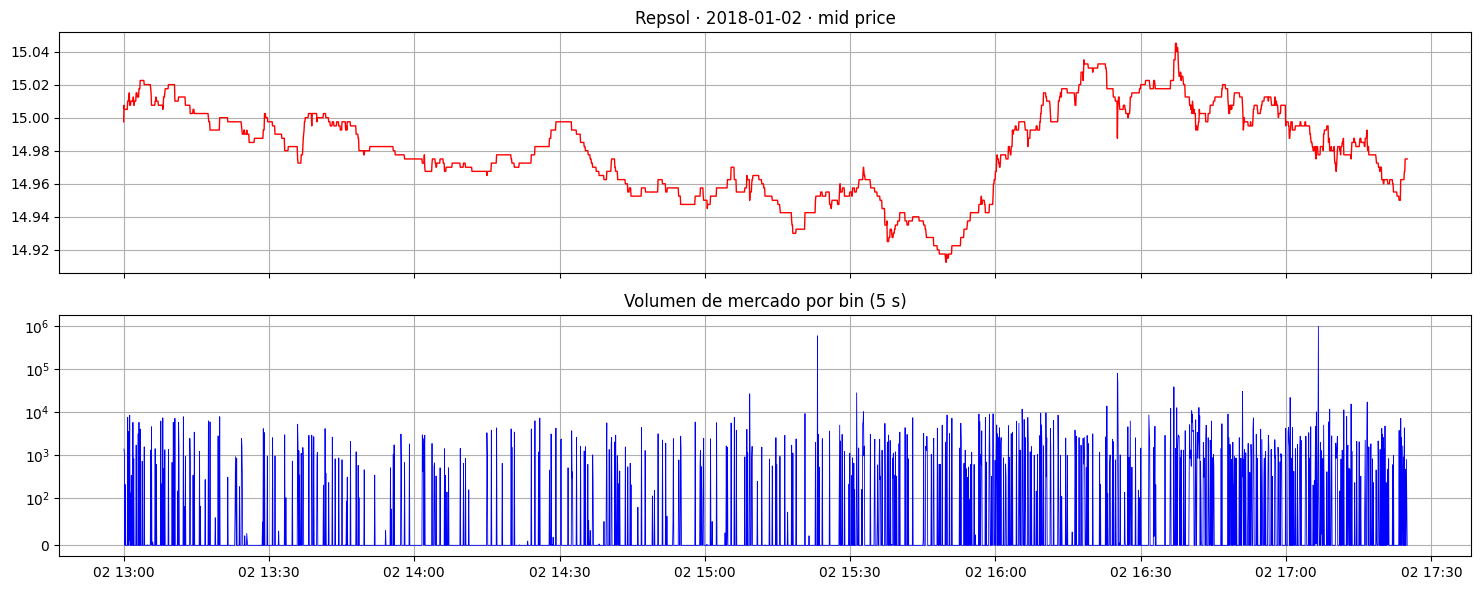

In [4]:
# ➕ Un día de ejemplo: mid price (arriba) y volumen negociado por bin de 5 s (abajo, escala symlog)
d = data[days[0]]
vol_bin = d["cumvol"].diff().clip(lower=0)
fig, ax = plt.subplots(2, 1, figsize=(15, 6), sharex=True)
ax[0].plot((d["ask1"] + d["bid1"]) / 2, color="red", lw=1)
ax[0].set_title(f"Repsol · {days[0]} · mid price"); ax[0].grid(True)
ax[1].plot(vol_bin, color="blue", lw=0.6)
ax[1].set_yscale("symlog", linthresh=100); ax[1].set_title("Volumen de mercado por bin (5 s)"); ax[1].grid(True)
plt.tight_layout(); plt.show()

**Lo que enseñan los datos y por qué importa para el entorno**

* Cada día es un `DataFrame` con un *bin* cada 5 s entre las 13:00 y las 17:25 (≈ 3 180 filas; algunos días tienen unos pocos bins menos, por eso el entorno indexa por posición y valida la longitud del episodio).
* El **volumen está extremadamente concentrado**: la mediana por bin es 0 y una fracción minúscula de bins concentra una parte muy grande del volumen total (cruces/bloques). Consecuencia: el VWAP de un episodio puede estar dominado por muy pocos *prints* y es un *benchmark* ruidoso → la recompensa heredará ese ruido.
* El volumen acumulado (`cumvol`) tiene **incrementos negativos** en *train* (correcciones de datos). No tienen sentido como volumen, así que el entorno los recorta a 0 (cambio nº 8).
* El *spread* medio ronda los 4 bps: comprar siempre en `ask1` cuesta, de media, la mitad del *spread* respecto al *mid*. Esto será clave para interpretar la recompensa.

---
# Entorno

### 2.1 Diseño del entorno: elementos de RL y decisiones

| Elemento | Implementación | Motivo |
|---|---|---|
| **Episodio / orden CARE** | Duración `episode_bins ~ U{400,…,600}` bins de 5 s (33–50 min) y orden de `vol_care = int(U(7.5 %, 12.5 %) × episode_bins)` títulos, en **órdenes hijas de 1 título** | Es la parametrización del enunciado; con hijas de 1 título, `vol_care` es el nº de compras necesarias y la participación requerida (`vol_care/episode_bins` ≈ 10 %) es comparable entre episodios |
| **`reset()`** | Elige día y hora de inicio al azar (con `look_back = 60` bins previos disponibles y sin salirse del día) | Distintas condiciones de partida en cada episodio (diapositivas: «el inicio no tiene por qué ser el mismo»); evita memorizar un único tramo de mercado |
| **Estado** `s = [time_left, vol_left]` | Tiempo restante (%) y volumen pendiente (%), ambos en [0, 1] | Es el estado mínimo y **markoviano** del problema de ejecución: lo único *privado* que el agente necesita para decidir «cuánto me queda y cuánto tiempo tengo». Normalizado → independiente del activo, del precio y del tamaño del episodio (estacionario) |
| **Acciones** | `0` = no hacer nada · `1` = compra **agresiva** de 1 título al `ask1` del bin actual | Espacio discreto mínimo (Q-learning exige acciones discretas). Cruzar el *spread* garantiza la ejecución en el simulador |
| **Transición** | Un step = un bin de 5 s; el mercado avanza solo (no hay impacto de mercado: nuestras órdenes no mueven el libro) | Simplificación del taller; se asume una profundidad suficiente en `ask1` para 1 título |
| **Recompensa** | Al comprar: `(VWAP_episodio − precio) / VWAP_episodio × 10⁴` (bps). Sin compra: `0` | Es el **VWAP slippage** con signo de compra (positivo = compré más barato que el mercado), el *benchmark* del sector. En bps para tener magnitudes O(1)–O(10) en lugar de O(10⁻⁴) y facilitar el aprendizaje con MSE |
| **Fin de episodio** | `done` si se agota el tiempo **o** si se completa la orden | Las dos condiciones naturales de una orden de ejecución |
| **VWAP del mercado** | Mid de cada bin ponderado por el volumen negociado en el bin siguiente | No hay ejecuciones de mercado en este fichero; se aproxima el precio de cada operación por el *mid* |

**Anti-fuga de información:** el VWAP del episodio (que usa datos futuros) solo lo emplea el simulador para calcular la recompensa; **no** está en el estado que ve el agente.

**Una propiedad que conviene tener presente:** al ser todas las órdenes de 1 título, la suma de recompensas sin descontar de un episodio vale exactamente `−(títulos ejecutados) × slippage_bps`. Es decir, el objetivo que se está optimizando es *minimizar títulos × slippage*. Si el *slippage* medio por compra es positivo (pagamos más que el VWAP), **ejecutar menos siempre «mejora» el retorno**. Lo retomamos en §5.4.

> 🔧 **BLOQUE MODIFICADO** — se completan los 13 `TODO` del entorno. Las líneas modificadas llevan el comentario `# 🔧`; la única adición en `step()` lleva `# ➕`.

In [5]:
class BestExecutionEnv:

    def __init__(self, data, look_back=60):
        """Inicialización de la clase del entorno que simula
        el libro de ordenes.
        ----------------------------------------------------
        Input:
            - data:
                Dataframe con los datos previamente
                agrupados del libro de órdenes.

            - look_back:
                Ventana para la generación de features
                roladas en el instante t=0 del episodio.
                Esta ventana representa el rango máximo para
                la construcción de features.
        ----------------------------------------------------
        Variables Internas:
            - episode_bins:
                Número de bines (steps) del episodio.
            - episode_full_len:
                Es igual a look_back + episode_bins.
            - vol_care:
                Volumen total (en títulos) de la orden care.
            - actions_fn:
                Diccionario con las posibles acciones del agente.
                Las claves acceden a la función que evalúa la acción
                tomada por el agente.
            - n_actions:
                Número de acciones posibles.
            - n_features:
                Número de características de los estados.
            - episode:
                Dataframe que contiene los steps y estados del episodio.
            - episode_full:
                Es el episode añadiendo el look_back antes del comienzo
                del episodio.
            - episode_vwap:
                VWAP de mercado al final del episodio.
            - market_ep_vol:
                Volumen (títulos) ejecutado por el mercado en cada bin del episodio.
            - state_pos:
                Número de step en el que nos encontramos.
            - exec_vol:
                Acumulado de títulos ejecutados por el algoritmo.
            - actions_hist:
                Lista de acciones tomadas por el algoritmo en cada step.
            - market_vwap_hist:
                Lista de VWAP de mercado en cada step.
            - reward_hist:
                Lista de rewards obtenidas en cada step.
            - price_hist:
                Lista de precios ejecutados en cada step.
            - vol_hist:
                Lista de títulos ejecutados en cada step.
        """

        # Fixed params
        self.data = data
        self.look_back = look_back
        self.episode_bins = None
        self.episode_full_len = None
        self.vol_care = None

        self.actions_fn = {
            0: self._do_nothing,
            1: self._agg_action,
        }

        self.n_actions = len(self.actions_fn)
        self.n_features = self._detect_num_feat()

        # Data variables
        self.episode = None
        self.episode_full = None

        # Env variables
        self.episode_vwap = None
        self.market_ep_vol = None
        self.state_pos = 0
        self.exec_vol = 0
        self.actions_hist = []
        self.algo_vwap_hist = []
        self.market_vwap_hist = []
        self.reward_hist = []
        self.price_hist = []
        self.vol_hist = []

    def _detect_num_feat(self):
        """Detecta el número de variables del estado.
        Función necesaria para adaptarse automaticamente a los
        cambios en las variables de observation_builder.
        """
        self._reset_env_episode_params()
        self._generate_episode()
        s = self.observation_builder()
        return s.shape[0]

    def _reset_env_episode_params(self):
        """
        Reset del episodio e inicialización de los parámetros.
        Las variables internas vuelven a sus valores originales.
        """
        self.episode_full_len = None
        self.episode = None
        self.episode_full = None
        self.episode_vwap = None
        self.market_ep_vol = None
        self.state_pos = 0
        self.algo_vwap = 0
        self.exec_vol = 0
        self.actions_hist = []
        self.algo_vwap_hist = []
        self.market_vwap_hist = []
        self.reward_hist = []
        self.price_hist = []
        self.vol_hist = []

    def _generate_episode_params(self):
        """(1) Se determinan las características de la orden a ejecutar.
        La orden queda definida por:
         - episode_bins:
             Obtención de un número entero aleatorio [400, 600]
             con una distribución uniforme.
         - vol_care:
             Obtención del porcentaje de steps en el que hay que
             ejecutar una orden para cubrir la orden care.
             vol_care responde a un valor uniforme [0.075, 0.125]
             multiplicado por el número self.episode_bins.
             Lo convertimos a entero.
        """
        # 🔧 Int aleatorio entre 400 y 600 (ambos incluidos) como un objeto numpy.
        #    np.random.randint excluye el extremo superior -> 601.
        self.episode_bins = np.random.randint(400, 601)
        # 🔧 Float aleatorio uniforme entre 0.075 y 0.125 (fracción de steps en los que hay que comprar)
        pct_bins = np.random.uniform(0.075, 0.125)
        # 🔧 Tamaño de la orden CARE en títulos = pct_bins * episode_bins, truncado a int
        #    (órdenes hijas de 1 título -> vol_care = nº de acciones agresivas necesarias)
        self.vol_care = int(pct_bins * self.episode_bins)

        self.episode_full_len = self.episode_bins + self.look_back

        assert self.episode_bins <= 600
        assert self.episode_bins >= 400
        assert self.vol_care <= int(self.episode_bins * 0.125)
        assert self.vol_care >= int(self.episode_bins * 0.075)
        assert isinstance(self.vol_care, int)

    def _generate_episode(self):
        """(2) Obtenemos el día y hora en el que comienza el episodio.
        """
        self._generate_episode_params()

        length_episode = 0
        while length_episode != self.episode_full_len:
            # 🔧 Selección de un día al azar entre los disponibles (las keys de data son fechas)
            selected_day = np.random.choice(list(self.data.keys()))

            # 🔧 Extraemos el DataFrame de ese día
            data_day = self.data[selected_day]

            # 🔧 Hora de inicio aleatoria: una marca temporal cualquiera del índice del día
            init_time = np.random.choice(data_day.index)

            hour_pos = data_day.index.get_loc(init_time)
            initial_position = hour_pos - self.look_back
            final_position = hour_pos + self.episode_bins

            if initial_position < 0:
                continue
            else:
                # 🔧 episode_full: look_back bins previos + los episode_bins del episodio.
                #    Si final_position se sale del día, el slice queda más corto y el
                #    while vuelve a muestrear (resample) otro día/hora.
                self.episode_full = data_day.iloc[initial_position:final_position]

                # 🔧 episode: solo los bins del episodio (desde hour_pos)
                self.episode = data_day.iloc[hour_pos:final_position]

                length_episode = self.episode_full.shape[0]


    def reset(self) -> np.array:
        """Reinicialización del episodio junto con los parámetros.
        Devuelve la primera observación del nuevo episodio.
        """
        self._reset_env_episode_params()
        self._generate_episode()
        self._compute_episode_market_feat()

        return self.observation_builder()

    def observation_builder(self) -> np.array:
        """(3) Función para la construcción de las observaciones del estado.
            ------------------------------------------------------------
            Default:
                - Primera característica es tiempo restante en porcentaje.
                - Segunda característica es el volumen restante en porcentaje.
        """
        # 🔧 Ambas variables en [0, 1] -> estacionarias y normalizadas (no dependen
        #    del activo, del precio ni del tamaño del episodio/orden).
        time_left = (self.episode_bins - self.state_pos) / self.episode_bins
        vol_left = (self.vol_care - self.exec_vol) / self.vol_care
        obs  = np.array([time_left, vol_left])

        return obs

    def _compute_episode_market_feat(self) -> Tuple[float, pd.Series]:
        """(4) Cálculo de los valores VWAP y Market Vol del episodio.
        Como no tenemos las ejecuciones de mercado, asumimos que el
        precio es el mid price de cada step.
        """
        # 🔧 Mid price de cada bin
        mid = (self.episode["ask1"] + self.episode["bid1"]) / 2
        # 🔧 Volumen del mercado en cada bin = incremento del volumen acumulado.
        #    Se recorta a 0 por calidad de datos: hay (muy pocos) incrementos negativos
        #    en train (correcciones del volumen acumulado) que no tienen sentido como volumen.
        self.market_ep_vol = self.episode["cumvol"].diff().clip(lower=0)
        self.market_ep_vol.iloc[0] = 0
        # 🔧 Volumen total negociado por el mercado en el episodio
        cum_vol = self.market_ep_vol.sum()
        # 🔧 VWAP del episodio: el mid de cada bin t se pondera con el volumen negociado
        #    justo después (bin t+1). .values para que pandas no alinee por índice.
        if cum_vol == 0:
            # Episodio sin ningún volumen de mercado: VWAP indefinido -> usamos el mid medio
            self.episode_vwap = mid.mean()
        else:
            self.episode_vwap = (mid.values[:-1] * self.market_ep_vol.values[1:]).sum() / cum_vol

        return self.episode_vwap, self.market_ep_vol

    def _compute_algo_vwap(self) -> float:
        """(8) Cálculo del VWAP del algoritmo hasta el step actual.
        """
        # 🔧 VWAP del algoritmo = sum(precio * volumen) / sum(volumen) con lo ejecutado hasta ahora
        p_arr = np.array(self.price_hist)
        v_arr = np.array(self.vol_hist)
        if v_arr.sum() == 0:
            # Todavía no hemos ejecutado nada: el VWAP no está definido
            # (NaN -> stats_df hace ffill y el gráfico no dibuja nada hasta la primera ejecución)
            return np.nan
        algo_vwap = (p_arr * v_arr).sum() / v_arr.sum()
        return algo_vwap

    def _compute_reward(self, price: float, vol: float) -> float:
        """(6) Función de diseño de los rewards y penalizaciones que
        recibe el algoritmo al tomar las acciones.
        --------------------------------------------------------
        Default:
            - El reward es el ratio de la diferencia entre el episode_vwap y
              el precio de la acción tomada, dividido entre episode_vwap.
        """
        # 🔧 Sin ejecución no hay slippage que premiar ni penalizar -> reward neutro
        if vol == 0:
            reward = 0.0
            return reward
        # 🔧 Reward por defecto: (VWAP - precio) / VWAP, expresado en puntos básicos (x 1e4).
        #    Compra: comprar por debajo del VWAP del episodio => reward > 0; por encima => < 0.
        #    Escala bps: mismo orden de magnitud que el slippage que queremos medir y rewards
        #    de O(1)-O(10) por orden (más cómodo para el MSE que ratios del orden de 1e-4).
        reward = (self.episode_vwap - price) / self.episode_vwap * 1e4
        return reward

    def _compute_stop_conditions(self) -> Tuple[bool, bool]:
        """(10) Define las condiciones de parada del episodio
        Return:
            Tiempo agotado, orden completada
        """
        # 🔧 Tiempo agotado: ya hemos consumido todos los bins del episodio
        is_bins_complete = self.state_pos >= self.episode_bins
        # 🔧 Orden completada: ya hemos comprado (al menos) todo el volumen de la orden CARE
        is_ord_complete = self.exec_vol >= self.vol_care
        return is_bins_complete, is_ord_complete

    def _compute_done_reward(self) -> float:
        """(12)
        """
        # 🔧 Free style: lo dejamos en 0 a propósito en el Ejercicio 1 (ver explicación del notebook).
        done_reward = 0
        return done_reward

    def _agg_action(self) -> float:
        """(7) Acción agresiva de compra de un título a precio de episode['ask1'].
        Devolvemos el reward asociado a esa acción.
        """
        # 🔧 Precio de la acción agresiva: ask1 del bin actual (acceso posicional por state_pos)
        price = self.episode["ask1"].iloc[self.state_pos]
        # 🔧 Registramos precio y volumen (1 título) y actualizamos el volumen ejecutado
        self.price_hist.append(price)
        vol = 1
        self.exec_vol += vol
        self.vol_hist.append(vol)

        # 🔧 VWAP del algoritmo tras esta ejecución, guardado en su histórico
        algo_vwap = self._compute_algo_vwap()
        self.algo_vwap_hist.append(algo_vwap)
        # 🔧 Reward asociado a esta ejecución
        reward = self._compute_reward(price, vol)
        return reward

    def _do_nothing(self) -> float:
        """(9) No hacer nada y devolvemos el reward asociado a la acción
        """
        # 🔧 Mismo proceso que _agg_action pero con precio y volumen ejecutado = 0
        price = 0
        vol = 0
        self.price_hist.append(price)
        self.vol_hist.append(vol)
        algo_vwap = self._compute_algo_vwap()
        self.algo_vwap_hist.append(algo_vwap)
        reward = self._compute_reward(price, vol)

        return reward

    def _compute_market_vwap(self) -> float:
        """(5) Cálculo del VWAP del mercado hasta el step actual.
        """
        # 🔧 Mismo criterio que en _compute_episode_market_feat: precio = mid de cada step...
        mid_p = (self.episode["ask1"] + self.episode["bid1"]) / 2
        mkt_p = mid_p
        # ...y volumen = el negociado en el bin siguiente (shift(-1)). El último step no tiene
        # bin siguiente -> fillna(0) (si no, el NaN contaminaría todas las sumas).
        v = self.market_ep_vol.shift(-1).fillna(0)
        # VWAP del mercado acumulado hasta el step actual (incluido)
        p_arr = mkt_p.values[:self.state_pos + 1]
        v_arr = v.values[:self.state_pos + 1]
        sum_vol = v_arr.sum()
        # Si el mkt vol hasta el step == 0, devolvemos el último precio hasta el step
        if sum_vol == 0:
            return p_arr[-1]
        # VWAP acumulado hasta el step
        market_vwap = (p_arr * v_arr).sum() / sum_vol
        return market_vwap

    def _compute_done(self) -> bool:
        """(11) Reglas de finalización del episodio.
        """
        # 🔧 Terminamos si se agota el tiempo o si se completa la orden (cualquiera de las dos)
        conditions = self._compute_stop_conditions()
        is_bins_complete, is_ord_complete = conditions
        done = is_bins_complete or is_ord_complete
        return done

    def step(self, action) -> Tuple[np.array, float, bool, dict]:
        """ Evalúa la acción, calcula la recompensa, devuelve el
        nuevo estado y si el episodio ha terminado.
        """
        market_vwap = self._compute_market_vwap()

        act_fn = self.actions_fn.get(action)
        if act_fn is None:
            raise ValueError(
                f"Invalid action {action}. Valid actions {self.actions_fn.keys()}"
            )

        reward = act_fn()

        # ➕ Guardamos la acción tomada (actions_hist estaba documentada pero nunca se rellenaba)
        self.actions_hist.append(action)
        self.market_vwap_hist.append(market_vwap)
        self.reward_hist.append(reward)

        self.state_pos += 1

        done = self._compute_done()

        if done:
            reward += self._compute_done_reward()
            return None, reward, done, {}

        observation = self.observation_builder()

        return np.array(observation), reward, done, {}

    def action_sample(self) -> int:
        """(13) Devuelve una acción aleatoria. El valor ha de corresponder
        con las keys de actions_fn.
        """
        # 🔧 Política aleatoria SESGADA hacia no hacer nada: comprar con probabilidad p igual a
        #    la participación que necesita la orden (vol_care / episode_bins ~ 7.5%-12.5%).
        #    Con p = 0.5 la orden se completaría en ~2*vol_care steps (~20% del episodio) y el
        #    buffer solo contendría estados con mucho tiempo restante; con p ~ vol_care/bins el
        #    comportamiento aleatorio recorre todo el episodio (time_left de 1 a 0).
        p = self.vol_care / self.episode_bins
        action = np.random.choice([0, 1], p=[1-p, p])
        return action

    def stats_df(self):
        """Información para el gráfico de resultados de la ejecución
        """

        my_df = pd.DataFrame(
            {"vwap": self.algo_vwap_hist, "vol": self.vol_hist},
            index=list(self.episode.index)[:len(self.algo_vwap_hist)]
        )
        my_df = my_df.reindex(self.episode.index)
        my_df["vol"] = my_df["vol"].fillna(0)
        my_df["vwap"] = my_df["vwap"].ffill()


        p = self.episode["ask1"]
        v = self.episode["cumvol"].diff().shift(-1)
        last_v = self.episode_full["cumvol"].diff().iloc[-1]
        v.iloc[-1] = last_v
        market_vwap = (p * v).cumsum() / v.cumsum()
        market_df = pd.DataFrame(
            {"vwap": market_vwap, "vol": v},
            index=v.index
        )

        mpx = (self.episode["ask1"] + self.episode["bid1"]) / 2

        return my_df, market_df, mpx

### 2.2 Verificación del entorno

Antes de entrenar hay que asegurarse de que el simulador cumple el contrato `reset()` / `step(a)` y de que sus magnitudes son coherentes. Se comprueban invariantes sobre cientos de episodios y se muestra la traza de un episodio paso a paso (estado → acción → recompensa).

> ➕ **BLOQUE AÑADIDO** — comprobaciones (`assert`) del entorno, traza de un episodio y función de métricas `episode_metrics`, que se usará en el entrenamiento y la evaluación.

In [6]:
env_check = BestExecutionEnv(dict_["train"], 60)
print(f"n_features = {env_check.n_features} | n_actions = {env_check.n_actions}")

# (1) Invariantes de reset(): 300 episodios aleatorios
for _ in range(300):
    s = env_check.reset()
    assert np.allclose(s, [1.0, 1.0]), "al empezar queda todo el tiempo y todo el volumen"
    assert 400 <= env_check.episode_bins <= 600
    assert int(env_check.episode_bins * 0.075) <= env_check.vol_care <= int(env_check.episode_bins * 0.125)
    assert env_check.episode.shape[0] == env_check.episode_bins
    assert env_check.episode_full.shape[0] == env_check.episode_bins + env_check.look_back
    assert env_check.episode.index[0] == env_check.episode_full.index[env_check.look_back]  # look_back previo
    mid = (env_check.episode["ask1"] + env_check.episode["bid1"]) / 2
    assert mid.min() <= env_check.episode_vwap <= mid.max()
print("✔ reset(): 300 episodios válidos (duración, tamaño de la orden, look_back y VWAP dentro del rango de precios)")

# (2) Invariantes de step(): 100 episodios con política aleatoria
n_full = 0
for _ in range(100):
    s, done, steps = env_check.reset(), False, 0
    while not done:
        s1, r, done, _ = env_check.step(env_check.action_sample())
        steps += 1
        if not done:
            assert s1.shape == (2,) and (0 <= s1).all() and (s1 <= 1).all()
    e = env_check
    assert steps == e.state_pos
    assert len(e.price_hist) == len(e.vol_hist) == len(e.algo_vwap_hist) == len(e.reward_hist) \
           == len(e.market_vwap_hist) == len(e.actions_hist) == steps
    assert sum(e.vol_hist) == e.exec_vol == sum(e.actions_hist)
    assert e.exec_vol >= e.vol_care or steps == e.episode_bins          # done solo por tiempo u orden completa
    assert e.exec_vol <= e.vol_care                                     # nunca se sobre-ejecuta
    if steps == e.episode_bins:                                         # episodio completo: el VWAP acumulado
        n_full += 1                                                     # del último step == VWAP del episodio
        assert abs(e.market_vwap_hist[-1] - e.episode_vwap) < 1e-9
print(f"✔ step(): 100 episodios coherentes (históricos alineados, no sobre-ejecución, VWAP incremental == VWAP del episodio en {n_full} episodios completos)")

n_features = 2 | n_actions = 2


✔ reset(): 300 episodios válidos (duración, tamaño de la orden, look_back y VWAP dentro del rango de precios)


✔ step(): 100 episodios coherentes (históricos alineados, no sobre-ejecución, VWAP incremental == VWAP del episodio en 46 episodios completos)


In [7]:
# Traza de un episodio: compramos en los steps 0, 4, 8 (acción 1) y esperamos en el resto (acción 0)
env_demo = BestExecutionEnv(dict_["train"], 60)
s = env_demo.reset()
rows = []
for t in range(12):
    a = 1 if t % 4 == 0 else 0
    s_next, r, done, _ = env_demo.step(a)
    rows.append({
        "t": t, "estado (T, V)": np.round(s, 3).tolist(), "acción": a, "reward (bps)": round(r, 2),
        "precio ejecutado": env_demo.price_hist[-1], "algo_vwap": env_demo.algo_vwap_hist[-1],
        "mkt_vwap": round(env_demo.market_vwap_hist[-1], 4), "done": done,
    })
    s = s_next
display(pd.DataFrame(rows).set_index("t"))
print(f"episode_bins = {env_demo.episode_bins} | vol_care = {env_demo.vol_care} | episode_vwap = {env_demo.episode_vwap:.4f}")


def episode_metrics(env) -> dict:
    """Métricas de un episodio TERMINADO (se llamó a env.step hasta done).
    slippage_bps = (VWAP algo - VWAP mercado) / VWAP mercado * 1e4  ->  en una compra, negativo = mejor que el mercado.
    Al ser órdenes de 1 título: sum_reward = - títulos ejecutados * slippage_bps.
    """
    prices = np.array(env.price_hist, dtype=float)
    vols = np.array(env.vol_hist, dtype=float)
    exec_vol = vols.sum()
    algo_vwap = (prices * vols).sum() / exec_vol if exec_vol > 0 else np.nan
    return {
        "bins": env.episode_bins, "vol_care": env.vol_care, "steps": env.state_pos,
        "exec_frac": exec_vol / env.vol_care, "time_frac": env.state_pos / env.episode_bins,
        "algo_vwap": algo_vwap, "mkt_vwap": env.episode_vwap,
        "slippage_bps": (algo_vwap - env.episode_vwap) / env.episode_vwap * 1e4,
        "sum_reward": float(np.sum(env.reward_hist)),
    }

,"estado (T, V)",acción,reward (bps),precio ejecutado,algo_vwap,mkt_vwap,done
t,,,,,,,
0,"[1.0, 1.0]",1,-13.05,14.165,14.165000,14.1600,False
1,"[0.998, 0.979]",0,0.00,0.000,14.165000,14.1600,False
2,"[0.996, 0.979]",0,0.00,0.000,14.165000,14.1600,False
3,"[0.994, 0.979]",0,0.00,0.000,14.165000,14.1575,False
4,"[0.992, 0.979]",1,-9.51,14.160,14.162500,14.1575,False
5,"[0.99, 0.958]",0,0.00,0.000,14.162500,14.1575,False
6,"[0.987, 0.958]",0,0.00,0.000,14.162500,14.1575,False
7,"[0.985, 0.958]",0,0.00,0.000,14.162500,14.1575,False
8,"[0.983, 0.958]",1,-9.51,14.160,14.161667,14.1575,False


episode_bins = 479 | vol_care = 48 | episode_vwap = 14.1465


La traza muestra el orden de la interacción dentro de un `step`: se evalúa el VWAP de mercado *antes* de actuar, se ejecuta la acción (precio, volumen, VWAP del algoritmo y reward con el precio del step actual), se guardan los históricos, se avanza `state_pos` y solo entonces se comprueba `done` y se construye la siguiente observación — de modo que el estado `s_{t+1}` ya refleja el tiempo consumido y el volumen ejecutado.

---
## 3. Benchmark determinista: TWAP

---
<center><h2>TWAP</h2></center>

<center>
<p style="width:80%">
El <b><i>time weighted average price</i></b> (TWAP) es un algoritmo tradicional de negociación basado en el precio medio ponderado por el tiempo, utilizado normalmente para la ejecución de órdenes grandes para reducir el impacto de mercado. Básicamente, se trocea la orden de manera que ejecute las órdenes en un tiempo equidistante durante el tiempo de ejecución seleccionado por el cliente. Puede ser fácil adivinar el patrón de negociación de la estrategia en ejecución si sus órdenes no se modifican de una manera especial, por lo que los parámetros se pueden ajustar o alterar para hacer que la estrategia sea más difícil de rastrear. Las soluciones más comunes son la aleatorización del tamaño de las órdenes y/o el tiempo de envío entre cada una de ellas. Es posible limitar la cantidad para que no exceda un porcentaje definido del volumen de participación, o también evitar agresiones de más de una posición del libro. Esto nos ayuda a minimizar el impacto de las estrategias en el mercado.
</p>  
<p style="width:80%">
Para el objetivo del taller, se pide a los participantes implementar un TWAP sin la necesidad de realizar ninguna modificación. El agente TWAP ha de trocear y ejecutar las órdenes hijas de la orden CARE equidistantes en el tiempo, sin necesidad de incorporar mecanismos para evitar su detección.
</p>

> 🔧 **BLOQUE MODIFICADO** — se implementa `act`. Un agente determinista es además una **prueba de humo** muy útil del entorno: si un TWAP no completa la orden en cada episodio, el simulador tiene un error.

In [8]:
class TWAP(DDQNAgent):
    def act(self, s): # [T, V]
        # 🔧 TWAP determinista a partir del estado s = [T, V] (tiempo restante, volumen restante, ambos en [0, 1]).
        #    Calendario lineal: tras consumir una fracción x del tiempo debería llevarse ejecutada una fracción x
        #    del volumen. Compramos siempre que vayamos igual o por detrás de ese calendario, es decir, cuando
        #    el volumen pendiente V >= tiempo restante T. La tolerancia 1e-9 evita fallos de comparación en coma
        #    flotante en los puntos de empate.
        #    Resultado: una compra cada ~ episode_bins / vol_care steps (equidistantes), la primera en t = 0
        #    y la última antes de agotar el tiempo.
        T, V = s
        a = int(V >= T - 1e-9)
        return a

episode_bins = 468 | vol_care = 46 | separación entre compras = [10, 11] steps (≈ bins/vol_care = 10.17)
bins            468.000
vol_care         46.000
steps           459.000
exec_frac         1.000
time_frac         0.981
algo_vwap        14.106
mkt_vwap         14.100
slippage_bps      4.231
sum_reward     -194.609


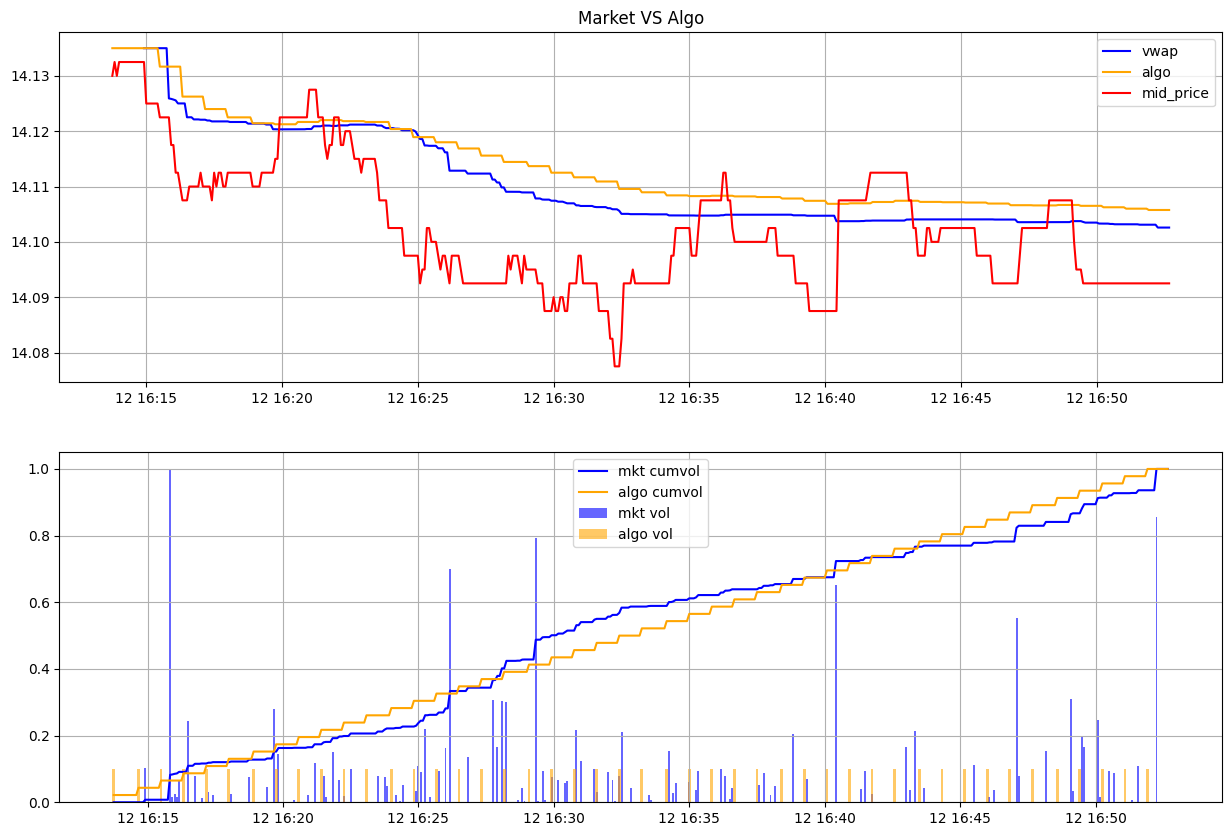

In [9]:
# ➕ Demo: TWAP sobre un episodio de train + gráfico estándar del repo (plot_results)
env_twap = BestExecutionEnv(data, 60)
twap = TWAP(env_twap)
np.random.seed(SEED + 1)
s, done = env_twap.reset(), False
while not done:
    s, r, done, _ = env_twap.step(twap.act(s))
buys = np.flatnonzero(env_twap.actions_hist)
print(f"episode_bins = {env_twap.episode_bins} | vol_care = {env_twap.vol_care} | "
      f"separación entre compras = {sorted(set(map(int, np.diff(buys))))} steps (≈ bins/vol_care = {env_twap.episode_bins / env_twap.vol_care:.2f})")
print(pd.Series(episode_metrics(env_twap)).round(3).to_string())
plot_results(env_twap)

El TWAP completa la orden con compras equidistantes (arriba, la línea naranja de volumen acumulado es una recta). Su *slippage* es **positivo** (unos pocos bps peor que el VWAP): paga `ask1` en vez del *mid* con el que se calcula el VWAP de referencia y no tiene ninguna información sobre el volumen de mercado. Este es el *benchmark* que, en los ejercicios siguientes, el agente de RL deberá igualar (Ejercicio 2) o mejorar (Ejercicio 4).

---
## 4. Parametrización del problema y agente

------------------
<center><h2>Parametrización del Problema</h2></center>

<center>
<p style="width:80%">
Una vez definido el entorno que vamos a utilizar como simulador de mercado, necesitamos definir el agente que va a encargarse de aprender a ejecutar las órdenes CARE. El agente es el <b><i>cerebro</i></b> del sistema y puede tener, o no, inteligencia artificial implementada. Por ejemplo, la clase TWAP anteriormente implementada depende únicamente de una regla determinista. Por otro lado, los algoritmos vistos durante el bloque de Aprendizaje por Refuerzo dependerán de la construcción de un modelo de aprendizaje y, por tanto, requerirán la parametrización de estos. Los parámetros e hiperparámetros del modelo dependerán de la aproximación y modelo que elijamos.
</p>
</center>

---
<center >
<p style="width:80%">
    <b>Epsilon</b>: Parámetro de exploración para los algoritmos basados en funciones valor (por ejemplo, los deep Q-learning). Puede tomar valores entre [0,1].
</p> 
</center>
<center>
<p style="width:80%">
    <b>Min Epsilon</b>: Valor mínimo del epsilon por si se quiere dejar aleatoriedad durante procesos de entrenamiento muy largos en los que el <b>epsilon</b> decaería hasta cero.
</p> 
</center>
<center>
<p style="width:80%">
    <b>Epsilon_decay</b>: Valor numérico mediante el cual se reduce el valor de epsilon cada determinado número de episodios.
</p> 
</center>
<center>
<p style="width:80%">
    <b>Gamma</b>: Término de descuento para el cálculo de los retornos acumulados con descuento. Dado que nuestro MDP se define con tareas episódicas gamma podrá tomar valores en el intervalo [0,1].
</p> 
</center>
<center>
<p style="width:80%">
    <b>Alpha</b>: Step-size, término indicando el tamaño de las actualizaciones durante el aprendizaje. Dado que nuestro problema es no estacionario (el sistema evoluciona en el tiempo) el alpha será un valor estático o adaptativo pero nunca un valor que decaiga a cero con el tiempo.
</p> 
</center>

<center>
<p style="width:80%">
    <b>Buffer Size</b>: Tamaño de la memoria encargada de obtener un conjunto de datos que aproximadamente sea independiente e idénticamente distribuido (i.i.d).
</p> 
</center>

---
<center>
<p style="width:80%">
<b>*Nota*</b>: Los parámetros que definen la arquitectura de la red dependen de lo flexible y compleja que se construyan en los agentes. Los agentes ofrecidos para el taller mantienen la filosofía del mismo y se mantendrán sencillos.
</p> 
</center>
<center>
<p style="width:80%">
    <b>Batch size</b>: Tamaño de los paquetes de datos que se envían al modelo durante su aprendizaje.
</p> 
</center>

<center>
<p style="width:80%">
    <b>Hidden_neurons</b>: Número de neuronas en las capas ocultas de los modelos.
</p> 
</center>

---
<center>
<p style="width:80%">
    <b>Nepisodes</b>: Número de sesiones de trading (episodios) que se van a realizar para el entrenamiento del modelo.
</p> 
</center>
<center>
<p style="width:80%">
    <b>N_log</b>: Valor numérico indicando cada cuántos episodios se realiza un log de la situación actual del aprendizaje.
</p> 
</center>
<center>
<p style="width:80%">
    <b>Learn_after</b>: Valor numérico indicando cada cuántos steps se realiza un aprendizaje por parte de las redes.
</p> 
</center>
<center>
<p style="width:80%">
    <b>Update_target_after</b>: Valor numérico indicando cada cuántos steps se copian los pesos de la red primary a la red target.
</p> 
</center>

### Valores elegidos

Según el enunciado, en este ejercicio **no es necesario motivar en detalle** la parametrización (no hay todavía un objetivo claro para el algoritmo); aun así se explica brevemente cada elección. Se ajustarán con criterio en el Ejercicio 2.

| Parámetro | Valor | Idea |
|---|---|---|
| `epsilon` / `min_epsilon` | 1.0 / 0.05 | Empezar explorando al 100 % (el buffer se rellena con acciones aleatorias) y dejar siempre un 5 % de exploración |
| `epsilon_decay` | `(1 − 0.05) / (0.8 · nepisodes)` | Decaimiento lineal por episodio hasta el mínimo en el 80 % del entrenamiento. Es un **placeholder** deliberadamente simple: el Ejercicio 3 lo sustituirá por un esquema ligado al aprendizaje |
| `gamma` | 0.99 | Tarea episódica larga (~500 steps); valor estándar que da peso al futuro sin hacer el objetivo excesivamente miope |
| `alpha` | 1e-3 | *Step-size* habitual de Adam; el 0.01 por defecto del agente es agresivo para una red pequeña. Constante (el problema es no estacionario) |
| `buffer_size` | 50 000 | ≈ 100 episodios de experiencia; compromiso entre independencia de las muestras y obsolescencia |
| `batch_size` | 64 | Tamaño estándar |
| `hidden_neurons` | 32 | La entrada solo tiene 2 variables: una red pequeña es suficiente |
| `nepisodes` | 300 | Suficiente para ver la convergencia de las curvas con un coste de unos 10 min |
| `learn_after`, `update_target_after` | `batch_size`, `10 · learn_after` | Valores fijados por el notebook original (aprender cada 64 steps; sincronizar la *target* cada 640) |

> 🔧 **BLOQUE MODIFICADO** — se rellenan todos los `"-----"` de la celda de parámetros y se re-siembra antes de crear el agente (el entrenamiento no depende de cuántas pruebas se hicieron antes).

In [10]:
"""
    Agent Params
"""
# 🔧 Epsilon inicial para el entrenamiento: exploración total al principio
epsilon = 1.0
# 🔧 Epsilon mínimo: se mantiene un 5 % de exploración
min_epsilon = 0.05
# 🔧 Factor de descuento
gamma = 0.99
# 🔧 Step-size (learning rate de Adam)
alpha = 1e-3
# 🔧 Tamaño del buffer de experiencias
buffer_size = 50_000
# 🔧 Tamaño del batch de aprendizaje
batch_size = 64
# 🔧 Neuronas de las capas ocultas
hidden_neurons = 32

"""
    Training Params
"""
# 🔧 Número de episodios de entrenamiento
nepisodes = 300
n_log = 25
# 🔧 Decaimiento lineal de epsilon por episodio: de `epsilon` a `min_epsilon` en el 80 % del entrenamiento
epsilon_decay = (epsilon - min_epsilon) / (0.8 * nepisodes)
learn_after = batch_size
# Cada cuántos pasos se copian los pesos del primary al target
update_target_after = 10 * learn_after

# 🔧 Re-semilla: el resultado no depende de las comprobaciones anteriores
np.random.seed(SEED)
tf.random.set_seed(SEED)

env = BestExecutionEnv(data, 60)
print(f"epsilon_decay = {epsilon_decay:.5f} | learn cada {learn_after} steps | update_target cada {update_target_after} steps")

epsilon_decay = 0.00396 | learn cada 64 steps | update_target cada 640 steps


<center><h3>Inicialización del agente</h3></center>

> 🔧 **BLOQUE MODIFICADO** — se completa `agent = "-----"`: Double DQN con los parámetros anteriores. Se añade el resumen de la arquitectura.

In [11]:
# 🔧 Double DQN (red primary + red target, Combined Experience Replay) con los parámetros elegidos
agent = DDQNAgent(
    env,
    gamma=gamma, epsilon=epsilon, alpha=alpha,
    batch_size=batch_size, buffer_size=buffer_size, hidden_neurons=hidden_neurons,
)
agent.primary_model.summary(line_length=72, print_fn=lambda x, **kw: print(x))   # ➕ arquitectura: 2 -> 32 -> 32 -> 2 (un Q-valor por acción)

Model: "functional_2"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape          ┃      Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)    │ (None, 2)             │            0 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ dense_6 (Dense)               │ (None, 32)            │           96 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ dense_7 (Dense)               │ (None, 32)            │        1,056 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ dense_8 (Dense)               │ (None, 2)             │           66 │
└───────────────────────────────┴───────────────────────┴──────────────┘
 Total params: 1,218 (4.76 KB)
 Trainable params: 1,218 (4.76 KB)
 Non-trainable params: 0 (0.00 B)



---
## 5. Entrenamiento

### 5.0 El orden de la interacción (qué ocurre y en qué orden)

```
env.reset() ──────────────► s_0                                   (episodio nuevo: día, hora, duración y orden aleatorios)
        │
        ▼
 ┌─►  a_t = agent.act(s_t)                  ε-greedy: con prob. ε acción aleatoria, si no argmax_a Q(s_t, a)
 │    s_{t+1}, r_t, done = env.step(a_t)    el entorno evalúa la acción, calcula el reward y avanza un bin
 │    agent.experience(s_t, a_t, r_t, s_{t+1}, done)      guarda la transición en el buffer (si done → s_{t+1} = None)
 │    cada `learn_after` steps:         agent.learn()          batch del buffer (CER) → objetivo Double DQN → 1 paso de gradiente
 │    cada `update_target_after` steps: agent.update_target()  copia los pesos primary → target
 │    s_t ← s_{t+1}
 └── si no done ──┘            si done → ε ← max(ε − epsilon_decay, min_epsilon) y siguiente episodio
```

* **Objetivo Double DQN** (lo implementa `DDQNAgent.learn`): `y = r + γ · Q_target(s', argmax_a' Q_primary(s', a'))`; si `s'` es terminal, `y = r`. La red *primary* **elige** la acción y la *target* (congelada, actualizada cada 640 steps) la **evalúa**, lo que reduce la sobreestimación de los Q-valores y estabiliza el aprendizaje.
* **Experience replay** (buffer FIFO con `deque`): se aprende de muestras aleatorias del pasado para romper la correlación entre transiciones consecutivas (i.i.d.). **CER** añade siempre la última experiencia al batch.
* **Off-policy:** la política de comportamiento (ε-greedy) no es la que se aprende (greedy). Por eso en la **evaluación** se desactiva la exploración (`set_trainable(False)`) y no se aprende.
* **Orden global:** (1) rellenar el buffer con política aleatoria → (2) entrenar con ε decreciente → (3) evaluar *greedy* sobre datos **no vistos** (*test*).

### 5.1 Relleno del buffer de experiencias

<center><h3>Recolección de los Episodios para el Buffer</h3></center>
<center>
<p style="width:80%">
Antes de empezar el entrenamiento, para que el modelo tenga experiencias de las que aprender y poder tomar acciones greedy con cierto criterio ha de tener muestras para entrenar. Para ello vamos a llenar el buffer con experiencias siguiendo una política estocástica con el objetivo de explorar el entorno inicialmente.
</p>

> 🟢 **SIN CAMBIOS** — código original, tal cual. Con ε = 1 todas las acciones son aleatorias (la acción aleatoria del entorno está sesgada hacia no comprar: cambio nº 9).

In [12]:
# En este punto eps es 1 -> actuando random
s = env.reset()
for exps in range(buffer_size):
    a = agent.act(s)
    s1, r, done, _ = env.step(a)
    agent.experience(s, a, r, s1, done)
    s = s1
    if not exps % 10000:
        print(f'buffer exps: {exps}')
    if done:
        s = env.reset()

buffer exps: 0


buffer exps: 10000


buffer exps: 20000


buffer exps: 30000


buffer exps: 40000


> ➕ **BLOQUE AÑADIDO** — resumen del contenido del buffer: comprobamos que la exploración cubre todo el espacio de estados antes de empezar a aprender.

experiencias: 50000 | % compras: 10.0% | % transiciones terminales: 0.21%
reward de las compras (bps): media -2.70, desv. 13.82


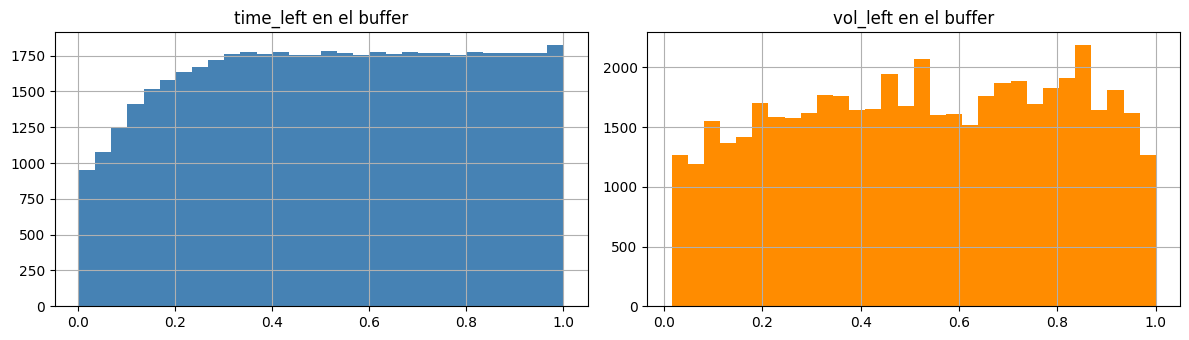

In [13]:
buf_s = np.array([e[0] for e in agent.buffer])
buf_a = np.array([e[1] for e in agent.buffer])
buf_r = np.array([e[2] for e in agent.buffer])
buf_terminal = np.array([e[3] is None for e in agent.buffer])
print(f"experiencias: {len(agent.buffer)} | % compras: {buf_a.mean() * 100:.1f}% | % transiciones terminales: {buf_terminal.mean() * 100:.2f}%")
print(f"reward de las compras (bps): media {buf_r[buf_a == 1].mean():.2f}, desv. {buf_r[buf_a == 1].std():.2f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].hist(buf_s[:, 0], bins=30, color="steelblue"); ax[0].set_title("time_left en el buffer"); ax[0].grid(True)
ax[1].hist(buf_s[:, 1], bins=30, color="darkorange"); ax[1].set_title("vol_left en el buffer"); ax[1].grid(True)
plt.tight_layout(); plt.show()

El buffer cubre todo el rango de `time_left` y `vol_left`, que es justo lo que buscaba la política aleatoria sesgada del entorno (con `p = 0.5` el episodio terminaría pronto y se habría concentrado en el inicio). La zona final de `time_left` está algo menos poblada porque en torno a la mitad de los episodios aleatorios completan la orden antes de agotar el tiempo. La proporción de compras ronda el 10 %, la participación que necesita la orden. Y un dato que importa mucho más adelante: **una compra aleatoria rinde, de media, un reward negativo** (≈ −2.7 bps con una desviación de ≈ 14 bps).

### 5.2 Bucle de entrenamiento

#### Train Algo

> 🔧 **BLOQUE MODIFICADO** — tres cambios (marcados con `# 🔧` / `# ➕`): (a) `mse = np.nan` antes del bucle, porque `mse` solo se asigna cuando toca aprender y se lee al final de **cada** episodio (un episodio de menos de 64 steps al comienzo provocaría un `NameError`); (b) se elimina el `mse = agent.learn()` del log: `learn()` no solo calcula el MSE, **da un paso de gradiente extra**, de modo que el log alteraba el entrenamiento y lo hacía depender de `n_log`; (c) se registran más métricas por episodio.

In [14]:
agent.set_trainable(True)
learn_counter = 0
history_steps = []
history_rewards = []
history_disc_rewards = []
history_losses = []
# ➕ Métricas adicionales por episodio (curvas de §5.3)
history_exec_frac = []
history_slippage = []
history_epsilon = []
mse = np.nan   # 🔧 evita NameError si un episodio termina antes del primer learn()
for episode in range(nepisodes):
    s = env.reset()
    step = 0
    cum_reward = 0
    dis_cum_reward = 0
    while True:
        a = agent.act(s)
        s1, r, done, _ = env.step(a)
        agent.experience(s, a, r, s1, done)
        learn_counter += 1
        cum_reward += r
        dis_cum_reward += agent.gamma ** step * r
        s = s1
        step += 1
        if not learn_counter % learn_after:
            mse = agent.learn()
        if not learn_counter % update_target_after:
            agent.update_target()
        if done:
            agent.epsilon = max([agent.epsilon - epsilon_decay, min_epsilon])
            m = episode_metrics(env)   # ➕
            history_rewards.append(cum_reward)
            history_disc_rewards.append(dis_cum_reward)
            history_losses.append(mse)
            history_steps.append(step)
            history_exec_frac.append(m["exec_frac"])        # ➕
            history_slippage.append(m["slippage_bps"])      # ➕
            history_epsilon.append(agent.epsilon)           # ➕
            if not episode % n_log:
                # 🔧 Original: `mse = agent.learn()` (paso de gradiente extra solo para imprimir). Ahora se muestra el último MSE.
                print(
                    f'Episode: {episode}, '
                    f'steps: {np.round(np.mean(history_steps[-n_log:]), 2)}, '
                    f'rew: {np.round(np.mean(history_rewards[-n_log:]), 2)}, '
                    f'exec: {np.round(np.mean(history_exec_frac[-n_log:]) * 100)}%, '   # ➕ % de la orden ejecutada
                    f'mse: {np.round(mse, 2)}, '
                    f'eps: {np.round(agent.epsilon, 2)}'
                )
            break

Episode: 0, steps: 538.0, rew: -396.72, exec: 91.0%, mse: 8.21, eps: 1.0


Episode: 25, steps: 477.36, rew: -89.76, exec: 93.0%, mse: 10.05, eps: 0.9


Episode: 50, steps: 493.4, rew: -142.59, exec: 84.0%, mse: 10.24, eps: 0.8


Episode: 75, steps: 500.6, rew: -129.47, exec: 78.0%, mse: 10.26, eps: 0.7


Episode: 100, steps: 506.92, rew: -29.62, exec: 71.0%, mse: 10.35, eps: 0.6


Episode: 125, steps: 491.16, rew: -100.31, exec: 60.0%, mse: 10.18, eps: 0.5


... (2 outputs left out)

Episode: 200, steps: 504.52, rew: -67.04, exec: 24.0%, mse: 9.32, eps: 0.2


Episode: 225, steps: 493.48, rew: -36.57, exec: 17.0%, mse: 8.88, eps: 0.11


Episode: 250, steps: 485.8, rew: -15.06, exec: 9.0%, mse: 8.46, eps: 0.05


Episode: 275, steps: 480.72, rew: -8.32, exec: 8.0%, mse: 8.09, eps: 0.05


### 5.3 Curvas de entrenamiento

> 🔧 **BLOQUE MODIFICADO** — el original solo dibujaba la media móvil (20 episodios) de los rewards: `pd.DataFrame(history_rewards).rolling(20).mean().plot()`. Esa curva se mantiene (panel 1) y se amplía con otros tres paneles.

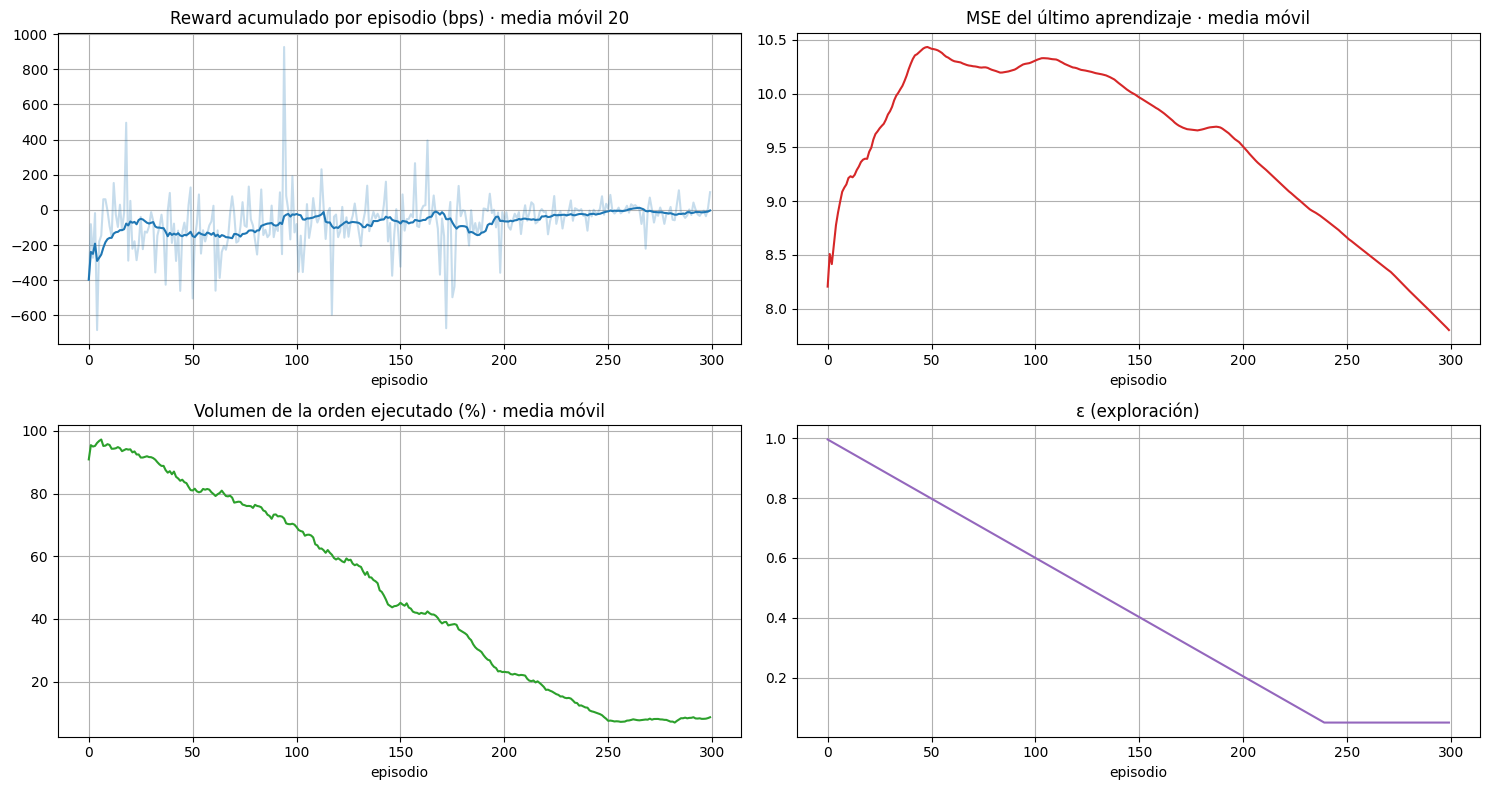

In [15]:
# 🔧 Original: pd.DataFrame(history_rewards).rolling(20).mean().plot()   (panel 1)
W = 20
roll = lambda x: pd.Series(x).rolling(W, min_periods=1).mean()
fig, ax = plt.subplots(2, 2, figsize=(15, 8))
ax[0, 0].plot(history_rewards, alpha=0.25, color="tab:blue"); ax[0, 0].plot(roll(history_rewards), color="tab:blue")
ax[0, 0].set_title(f"Reward acumulado por episodio (bps) · media móvil {W}")
ax[1, 0].plot(roll(history_exec_frac) * 100, color="tab:green"); ax[1, 0].set_title("Volumen de la orden ejecutado (%) · media móvil")
ax[0, 1].plot(pd.Series(history_losses).rolling(W, min_periods=1).mean(), color="tab:red"); ax[0, 1].set_title("MSE del último aprendizaje · media móvil")
ax[1, 1].plot(history_epsilon, color="tab:purple"); ax[1, 1].set_title("ε (exploración)")
for a_ in ax.ravel():
    a_.grid(True); a_.set_xlabel("episodio")
plt.tight_layout(); plt.show()

**Lectura de las curvas**

* El entrenamiento es **estable**: la pérdida (MSE) se mantiene acotada (≈ 8–10) y no diverge. *(Matiz: el valor que devuelve `DDQNAgent.learn()`, y que dibuja el panel de la pérdida, es el de `train_on_batch` de Keras 3, que es una **media acumulada** desde el primer aprendizaje y no la pérdida de cada batch. Sirve para descartar divergencias, pero está muy suavizado. El Ejercicio 2 registra la pérdida real de cada batch.)* Con ε alto el agente ejecuta casi toda la orden (≈ 95 % al principio) y el reward acumulado por episodio es muy negativo (≈ −130 de media y ≈ −400 en el primer episodio): cada compra aleatoria cuesta ≈ 2.7 bps de media (§5.1) y se hacen unas 50.
* A medida que ε baja, el volumen ejecutado cae hasta ≈ 8 % y el reward acumulado se acerca a 0. Ese 8 % residual es la exploración que queda (ε = 0.05) más la compra forzada del primer step; en modo *greedy* será ≈ 2 % (§6).
* Es decir, el agente **sí aprende**, pero converge a una política que **deja de comprar**. No es un fallo del código: es el comportamiento óptimo *para la recompensa tal y como está definida* (se demuestra en §5.4).
* Las métricas durante el entrenamiento están contaminadas por la exploración (ε); la medida limpia es la evaluación *greedy* de §6.

### 5.4 Diagnóstico: ¿qué ha aprendido el agente?

Para entender el resultado se inspecciona la red directamente: para una malla de estados `(time_left, vol_left)` se calcula la **ventaja de comprar**, `Q(s, comprar) − Q(s, esperar)`. Si es negativa en todas partes, la política *greedy* nunca compra.

> ➕ **BLOQUE AÑADIDO** — análisis de los Q-valores aprendidos (no existía en el notebook original).

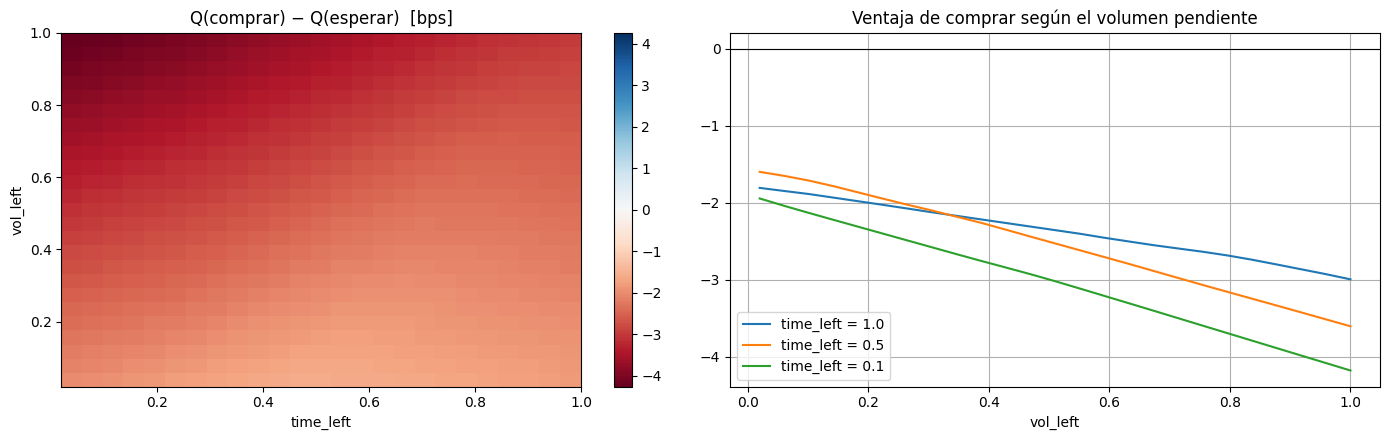

Fracción de estados de la malla donde comprar es preferible: 0.0%
Ventaja media de comprar: -2.62 bps  (compárese con el spread medio de ~4 bps: la mitad es lo que cuesta cruzarlo)


In [16]:
Ts = np.linspace(0.02, 1.0, 25)
Vs = np.linspace(0.02, 1.0, 25)
grid = np.array([[T, V] for V in Vs for T in Ts])                  # filas: V, columnas: T
Q = agent.getQs(grid, agent.primary_model)
adv = (Q[:, 1] - Q[:, 0]).reshape(len(Vs), len(Ts))                # Q(comprar) - Q(esperar), en bps

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
lim = np.abs(adv).max()
im = ax[0].imshow(adv, origin="lower", extent=[Ts[0], Ts[-1], Vs[0], Vs[-1]], aspect="auto", cmap="RdBu", vmin=-lim, vmax=lim)
ax[0].set_xlabel("time_left"); ax[0].set_ylabel("vol_left"); ax[0].set_title("Q(comprar) − Q(esperar)  [bps]")
plt.colorbar(im, ax=ax[0])
for T in (1.0, 0.5, 0.1):
    qs = agent.getQs(np.array([[T, V] for V in Vs]), agent.primary_model)
    ax[1].plot(Vs, qs[:, 1] - qs[:, 0], label=f"time_left = {T}")
ax[1].axhline(0, color="k", lw=0.8); ax[1].set_xlabel("vol_left"); ax[1].set_title("Ventaja de comprar según el volumen pendiente")
ax[1].legend(); ax[1].grid(True)
plt.tight_layout(); plt.show()
print(f"Fracción de estados de la malla donde comprar es preferible: {(adv > 0).mean() * 100:.1f}%")
print(f"Ventaja media de comprar: {adv.mean():.2f} bps  (compárese con el spread medio de ~4 bps: la mitad es lo que cuesta cruzarlo)")

**Interpretación.** La ventaja de comprar es **negativa en todos los estados de la malla** (entre ≈ −1.6 y ≈ −4.3 bps, media ≈ −2.6 bps), es decir, del orden de **medio *spread***. La razón es el diseño de la recompensa por defecto:

1. Cada compra tiene un reward esperado negativo: se paga `ask1` y se compara con un VWAP calculado sobre *mids* → coste ≈ medio *spread* más el ruido de precio. En el buffer (§5.1) una compra aleatoria rinde de media ≈ −2.7 bps.
2. El estado `[time_left, vol_left]` **no contiene ninguna información de precio ni de mercado**, así que el agente no puede elegir *cuándo* comprar para pagar menos que el VWAP: el *timing* es indistinguible de aleatorio. (La prueba está en §6.3: TWAP y política aleatoria, ninguna con habilidad de *timing*, tienen el mismo *slippage* medio.)
3. No hay ninguna recompensa (o castigo) por **completar la orden** (`_compute_done_reward = 0`) ni por terminar a tiempo.

Con (1)–(3), la política que maximiza el retorno es **no operar**. El agente ha hecho exactamente lo que se le pedía maximizar: es la lección de las diapositivas — *«el algoritmo hace lo que sea con tal de conseguir la mayor recompensa»* y *«la recompensa debe guardar relación con el comportamiento u objetivo deseado»*. El diseño de la recompensa (Ejercicio 2: replicar un TWAP; Ejercicio 4: penalizar volumen pendiente) es lo que corrige este comportamiento. Con este notebook el **pipeline completo ya funciona**: lo que cambia después es el objetivo.

> Nota: `DDQNAgent.act` fuerza la acción `1` en el primer step de cada episodio (regla del agente proporcionado), por lo que el agente siempre compra el primer título; el resto de la orden queda sin ejecutar.

---
## 6. Ejecución sobre datos no vistos (*test*)

### 6.1 Un episodio de *test* con el agente entrenado

#### Plot Results

> 🔧 **BLOQUE MODIFICADO** — (a) `agent.env = env`: el original crea un entorno nuevo para el *test* pero el agente sigue apuntando al de *train*; `DDQNAgent.act` lee `self.env.state_pos` (para forzar la compra del primer step) y `self.env.action_sample()`, de modo que en el *test* se miraba el contador de un entorno ya terminado y la regla del primer step no se aplicaba; (b) el descuento usa el índice de step **anterior** al incremento (`gamma ** step` con `step` empezando en 0, igual que en el entrenamiento); (c) el episodio se fija con una semilla para poder compararlo luego con el TWAP.

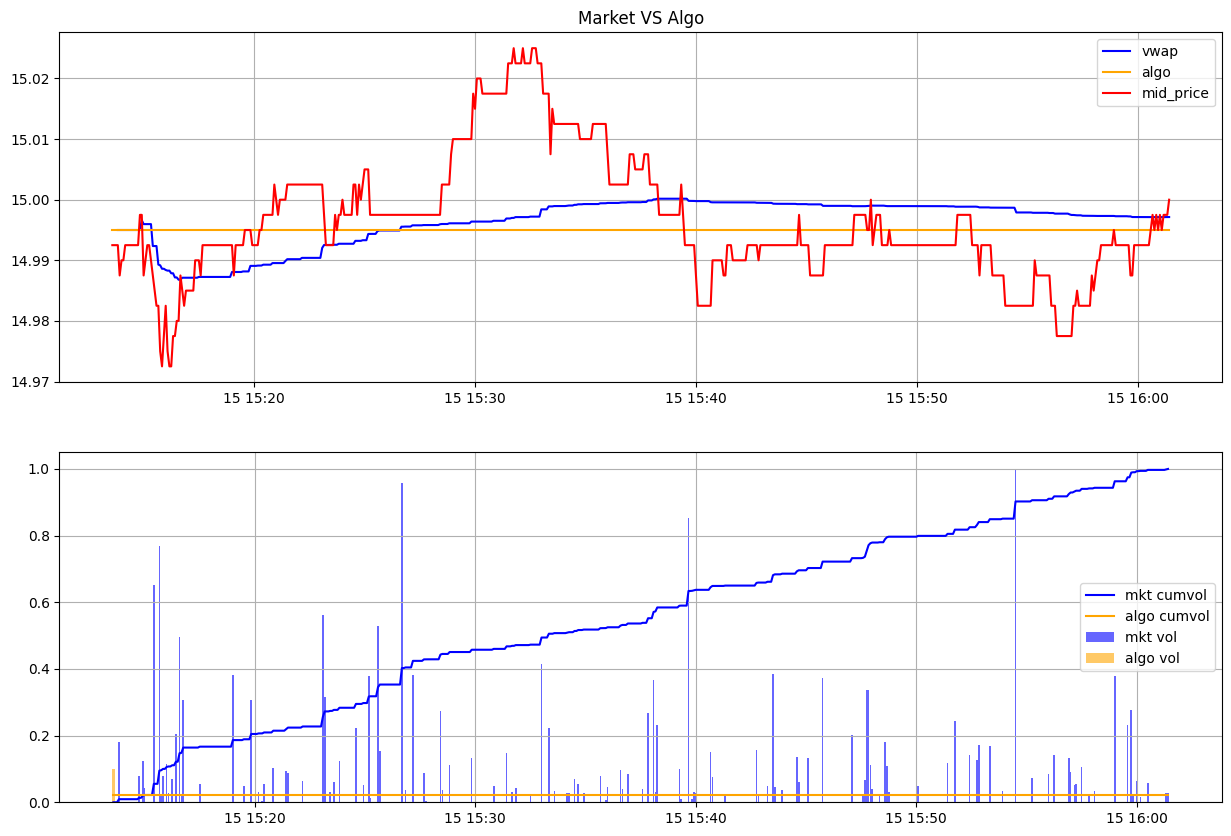

In [17]:
SEED_TEST_EP = 7   # ➕ episodio de test fijo (mismo día/hora/duración/orden para comparar después)

agent.set_trainable(False)
cum_reward = 0
step = 0
env = BestExecutionEnv(dict_["test"], 60)
agent.env = env          # 🔧 el agente debe consultar el entorno que realmente está ejecutando
np.random.seed(SEED_TEST_EP)
s = env.reset()
while True:
    a = agent.act(s)
    s, r, done, _ = env.step(a)
    cum_reward += agent.gamma ** step * r      # 🔧 índice de step previo al incremento
    step += 1
    if done:
        break
plot_results(env)

In [18]:
# ➕ Métricas del episodio de test
print(f"Reward descontado: {cum_reward:.3f}")
print(pd.Series(episode_metrics(env)).round(3).to_string())

Reward descontado: -0.494
bins            575.000
vol_care         49.000
steps           575.000
exec_frac         0.020
time_frac         1.000
algo_vwap        14.995
mkt_vwap         14.994
slippage_bps      0.494
sum_reward       -0.494


### 6.2 El mismo episodio con el TWAP

Mismo día, misma hora, misma duración y misma orden (se fija la semilla antes de `reset()`), pero ejecutada con el TWAP de §3.

> ➕ **BLOQUE AÑADIDO** — comparación visual sobre el episodio idéntico.

bins            575.000
vol_care         49.000
steps           565.000
exec_frac         1.000
time_frac         0.983
algo_vwap        14.999
mkt_vwap         14.994
slippage_bps      3.284
sum_reward     -160.926


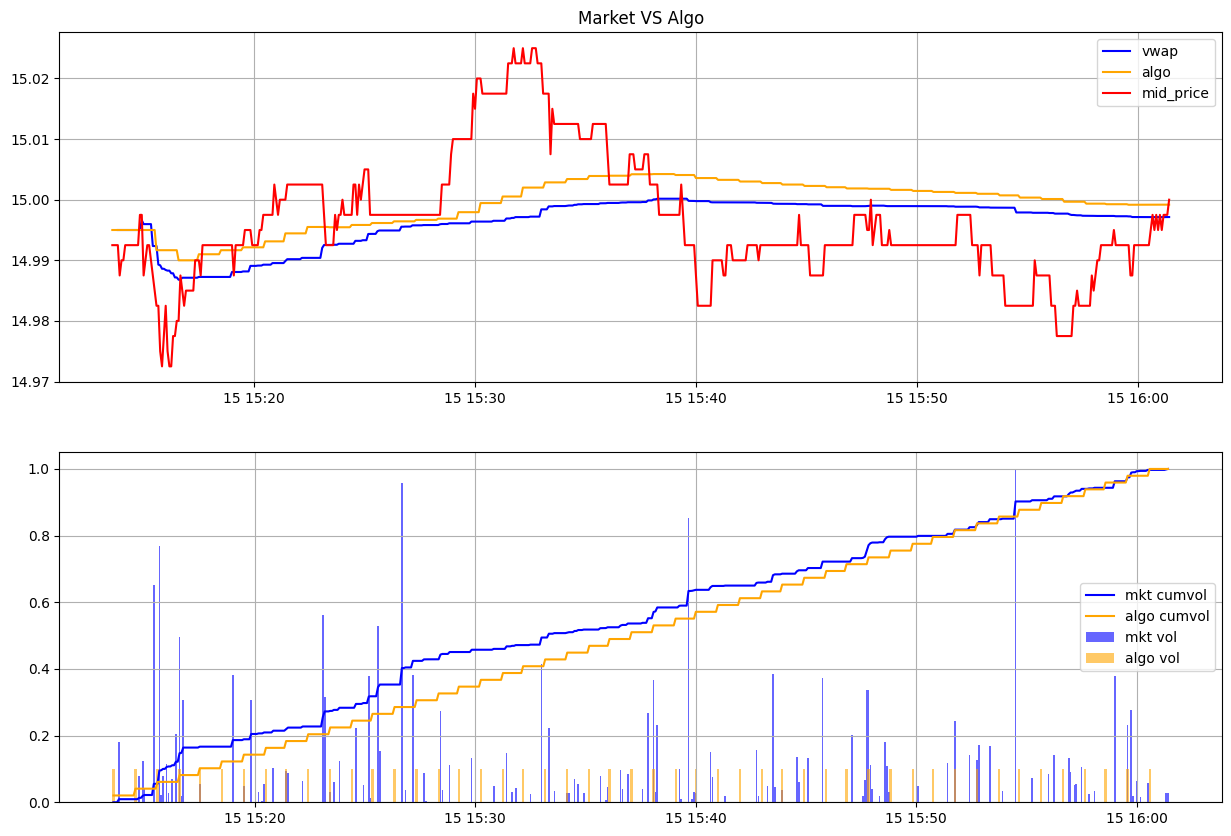

In [19]:
env_twap_test = BestExecutionEnv(dict_["test"], 60)
twap_test = TWAP(env_twap_test)
np.random.seed(SEED_TEST_EP)
s, done = env_twap_test.reset(), False
while not done:
    s, r, done, _ = env_twap_test.step(twap_test.act(s))
print(pd.Series(episode_metrics(env_twap_test)).round(3).to_string())
plot_results(env_twap_test)

### 6.3 Evaluación sobre 40 episodios de *test*: RL vs TWAP vs política aleatoria

Un único episodio no dice nada estadísticamente. Se evalúan tres políticas sobre **los mismos 40 episodios** de *test* (se siembra el generador antes de cada `reset()`, así que día, hora, duración y tamaño de la orden coinciden entre políticas):

* **Double DQN** entrenado (*greedy*, sin aprendizaje ni exploración),
* **TWAP** determinista (benchmark),
* **Aleatoria** (la política de exploración del entorno: comprar con probabilidad `vol_care / episode_bins`).

Métrica principal: **VWAP slippage en bps** (compra: negativo = mejor que el mercado), junto con el **% de la orden ejecutado** — un algoritmo de ejecución debe cumplir *ambas* cosas.

> ➕ **BLOQUE AÑADIDO** — evaluación comparativa y gráficos.

,Double DQN (greedy),TWAP,Aleatoria
volumen ejecutado (% de la orden),2.07,100.00,95.17
episodios con la orden completa (%),0.00,100.00,65.00
tiempo usado (% del episodio),100.00,98.23,93.19
slippage vs VWAP (bps) · media,5.45,2.81,2.81
slippage vs VWAP (bps) · desv. típica,12.87,3.81,4.28
suma de rewards (bps) · media,-5.45,-130.46,-123.56


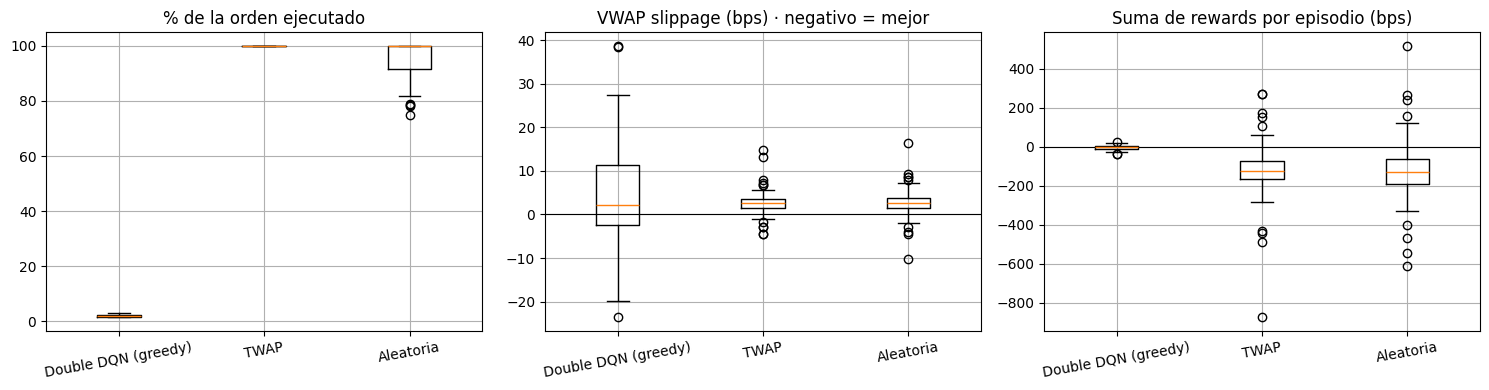

In [20]:
def run_episode(env, policy):
    s, done = env.reset(), False
    while not done:
        s, r, done, _ = env.step(policy(s))
    return episode_metrics(env)


def evaluate(env, policy, n_episodes=40, seed0=10_000):
    rows = []
    for i in range(n_episodes):
        np.random.seed(seed0 + i)       # mismo episodio para todas las políticas
        rows.append(run_episode(env, policy))
    return pd.DataFrame(rows)


eval_env = BestExecutionEnv(dict_["test"], 60)
agent.set_trainable(False)
agent.env = eval_env                     # 🔧 mismo motivo que en §6.1
twap_eval = TWAP(eval_env)

results = {
    "Double DQN (greedy)": evaluate(eval_env, agent.act),
    "TWAP": evaluate(eval_env, twap_eval.act),
    "Aleatoria": evaluate(eval_env, lambda s: eval_env.action_sample()),
}


def summarize(df):
    return pd.Series({
        "volumen ejecutado (% de la orden)": df.exec_frac.mean() * 100,
        "episodios con la orden completa (%)": (df.exec_frac >= 1).mean() * 100,
        "tiempo usado (% del episodio)": df.time_frac.mean() * 100,
        "slippage vs VWAP (bps) · media": df.slippage_bps.mean(),
        "slippage vs VWAP (bps) · desv. típica": df.slippage_bps.std(),
        "suma de rewards (bps) · media": df.sum_reward.mean(),
    })


summary = pd.DataFrame({name: summarize(df) for name, df in results.items()}).round(2)
display(summary)

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
names = list(results)
ax[0].boxplot([results[n].exec_frac * 100 for n in names]); ax[0].set_title("% de la orden ejecutado")
ax[1].boxplot([results[n].slippage_bps.dropna() for n in names]); ax[1].axhline(0, color="k", lw=0.8)
ax[1].set_title("VWAP slippage (bps) · negativo = mejor")
ax[2].boxplot([results[n].sum_reward for n in names]); ax[2].axhline(0, color="k", lw=0.8)
ax[2].set_title("Suma de rewards por episodio (bps)")
for a_ in ax:
    a_.set_xticks(range(1, len(names) + 1)); a_.set_xticklabels(names, rotation=10); a_.grid(True)
plt.tight_layout(); plt.show()

**Lectura de la tabla**

* **TWAP:** completa la orden en el 100 % de los episodios usando ≈ 98 % del tiempo; su *slippage* medio es ≈ +2.8 bps (alrededor de medio *spread*, que en *test* es ≈ 4.1 bps) con una desviación de ≈ 3.8 bps.
* **Aleatoria:** el mismo *slippage* medio (≈ 2.8 bps: no tiene ninguna habilidad de *timing*), algo más dispersa y sin garantía de completar la orden (solo ≈ 65 % de los episodios).
* **Double DQN:** ejecuta ≈ 2 % de la orden —exactamente el título que compra la regla del primer step— y **no completa ninguna**. Su «*slippage*» (≈ 5.5 bps) se calcula sobre ese único título, así que es ruido y **no es comparable** con los otros dos.
* Y sin embargo es la política con **mejor suma de rewards** (≈ −5 bps frente a ≈ −125/−130 bps): el agente optimiza exactamente lo que se le premia, no lo que se pretende. Es el ejemplo de manual de la advertencia de las diapositivas sobre el diseño de recompensas.

---
## 7. Conclusiones

### Qué se ha conseguido (requisitos del Ejercicio 1)

1. **Entorno de RL completo** (`BestExecutionEnv`): estado normalizado y markoviano, acciones discretas, recompensa (VWAP *slippage* en bps), transición, condiciones de fin de episodio y `reset()` aleatorio (día, hora, duración y tamaño de la orden). Verificado con invariantes sobre cientos de episodios (§2.2) y con un agente determinista (TWAP) que completa la orden siempre.
2. **Entrenamiento completo y en el orden correcto** para Double DQN (§5): buffer rellenado con política aleatoria → bucle `act → step → experience → learn → update_target` con ε decreciente → evaluación *greedy*, sin aprendizaje, sobre datos no vistos. 300 episodios, ≈ 10 min en CPU, pérdida sin divergencias (media acumulada, ver el matiz de §5.3).
3. **Ejecución completa sobre *test*** (§6): un episodio con su gráfico, el mismo episodio con el TWAP y una comparación sobre 40 episodios idénticos para RL, TWAP y política aleatoria.
4. **Documentación:** cada bloque modificado está marcado (🔧/➕/🟢) y listado en el registro de cambios (§0), con la lógica y el motivo de cada decisión. Se han detectado y corregido cuatro problemas del notebook original: la carga de los `.pkl` con pandas ≥ 2.1, `agent.env` apuntando al entorno de *train* durante el *test*, el `agent.learn()` oculto en el log (un paso de gradiente extra) y un `NameError` latente con `mse`.

### Qué dicen los resultados

* El *pipeline* funciona y es estable, pero el agente converge a **no operar** (solo compra el título que fuerza la regla del primer step). Es la política óptima **para la recompensa tal y como está definida**, no un fallo de implementación: cada compra tiene un reward esperado negativo (medio *spread*), el estado no contiene información que permita comprar «en mejor momento» y nada premia completar la orden.
* Como todas las órdenes son de 1 título, la suma de rewards es `−(títulos ejecutados) × slippage`: mientras el *slippage* medio sea positivo, **ejecutar menos siempre «mejora» el retorno**. Por eso el DQN «gana» en rewards y a la vez es inservible como algoritmo de ejecución.
* TWAP y política aleatoria tienen el mismo *slippage* medio (≈ 2.8 bps): sin información de mercado en el estado, ninguna política puede batir al VWAP por *timing*. La mejora respecto al TWAP (Ejercicio 4) exigirá incorporar variables del libro de órdenes.

### Limitaciones (de este ejercicio y del simulador)

* Sin impacto de mercado ni costes de transacción; se asume que `ask1` absorbe 1 título.
* El VWAP de referencia se aproxima con el *mid* y es ruidoso: ≈ 65 % del volumen está en el 1 % de los bins (§1.3).
* Hiperparámetros sin ajustar (Ejercicio 2), decaimiento de ε fijado por nº de episodios (Ejercicio 3), una sola semilla (no se ha medido la variabilidad entre entrenamientos), sin *early stopping* ni *checkpoints* de pesos.
* Se evalúa solo sobre *test*; la partición de validación (2019) queda reservada para el ajuste de hiperparámetros.

### Siguientes pasos (Ejercicios 2–4)

* **Ejercicio 2:** rediseñar la recompensa para replicar un TWAP (por ejemplo, premiar comprar cuando se va por detrás del calendario lineal `vol_left ≥ time_left` y penalizar ir muy por delante o por detrás), con ajuste y motivación de `gamma`, buffer y número de episodios.
* **Ejercicio 3:** `ε` ligado al aprendizaje (bajarlo cuando mejore la media móvil de una métrica de evaluación *greedy* frente al TWAP) en lugar de al nº de episodios.
* **Ejercicio 4:** penalización por volumen pendiente / uso del ~90 % del tiempo (Idea B), variables de libro de órdenes en el estado (Idea A), *checkpoints* y parada temprana (Idea C).